# VideoMamba-Tiny — CTPGesture_v1 Baseline

This notebook fine-tunes **VideoMamba-Tiny** on the original dataset structure:

```text
CTPGesture_v1/
└── police_gesture_v1/
    ├── train/
    └── test/
```

The notebook **does not move, rename, or modify the dataset structure provided by the original source**. It only creates annotation/index files under `/kaggle/working`.

### Fixed baseline configuration

- 9 classes: `0 = No Gesture`, `1..8 = traffic-police gestures`
- Each contiguous run in a CSV file is treated as one temporal sample; **short gaps are not merged**
- Train/validation split is performed by **video**, not by frame or segment:
  - Train: `001,005,007,009,013,015,017,101,103`
  - Validation: `003,011`
  - Test: keep the official `test/` split unchanged
- VideoMamba-Tiny, 16 frames, sampling rate 2, 224×224
- AdamW, learning rate `1e-4`, 30 epochs, 5 warmup epochs
- Effective batch size: 8
- FP32 training (`--no_amp`)
- Horizontal flip OFF; Mixup/CutMix OFF
- Final evaluation: single-view + 12-view (`4 temporal × 3 spatial`)
- Reports: Accuracy, Balanced Accuracy, Macro-F1, per-class metrics, confusion matrix, **parameter count, and GFLOPs**

### Kaggle inputs required before running

1. The notebook output or dataset containing `CTPGesture_v1/police_gesture_v1`.
2. The private CUDA wheel dataset used by the previous notebook: `hoanganh94/videomamba-t4-cuda-wheels`.
3. Enable **Internet** so the notebook can clone VideoMamba and download the pretrained checkpoint.


> **Runtime requirement:** this CP312 edition must run under **Python 3.12** and uses the prebuilt `hoanganh94/videomamba-t4-cuda-wheels` input. It intentionally does not build CPython 3.13 CUDA wheels.


In [1]:
import sys
import torch

print("Python :", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA   :", torch.version.cuda)

Python : 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
PyTorch: 2.10.0+cu128
CUDA   : 12.8


In [2]:
from pathlib import Path

for p in Path("/kaggle/input").rglob("*.whl"):
    print(p)

/kaggle/input/datasets/hoanganh94/videomamba-t4-cuda-wheels-cp312-v2/mamba_ssm-1.0.1-cp312-cp312-linux_x86_64.whl
/kaggle/input/datasets/hoanganh94/videomamba-t4-cuda-wheels-cp312-v2/causal_conv1d-1.0.0-cp312-cp312-linux_x86_64.whl


## CELL 1 — Experiment Configuration and GPU Check


In [3]:
import os
import random
from pathlib import Path

import numpy as np
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# ============================================================
# Dataset / split
# ============================================================

NUM_CLASSES = 9

CLASS_NAMES = {
    0: "No Gesture",
    1: "Stop",
    2: "Forward",
    3: "Left Turn",
    4: "Left Turn Waiting",
    5: "Right Turn",
    6: "Lane Changing",
    7: "Slow Down",
    8: "Pull Over",
}
TRAIN_IDS = [
    "001",
    "005",
    "007",
    "009",
    "013",
    "015",
    "017",
    "103",
]

VAL_IDS = [
    "003",
    "011",
]

TEST_IDS = [
    "002",
    "004",
    "008",
    "010",
    "012",
    "014",
    "016",
    "018",
    "101",
    "102",
    "104",
]

# ============================================================
# VideoMamba
# ============================================================

MODEL_NAME = "videomamba_tiny"
NUM_FRAMES = 16
SAMPLING_RATE = 2
TUBELET_SIZE = 1
INPUT_SIZE = 224
SHORT_SIDE_SIZE = 224

TRAIN_BATCH_SIZE = 2
TARGET_EFFECTIVE_BATCH = 8

LR = 1e-4
MIN_LR = 1e-6
WARMUP_LR = 1e-6
WARMUP_EPOCHS = 5
EPOCHS = 30

WEIGHT_DECAY = 0.05
LAYER_DECAY = 0.75
DROP_PATH = 0.1
FC_DROP_RATE = 0.3
CLIP_GRAD = 1.0

TEST_NUM_SEGMENT = 4
TEST_NUM_CROP = 3

# ============================================================
# Paths
# ============================================================

WORK_ROOT = Path("/kaggle/working")
REPO_DIR = WORK_ROOT / "VideoMamba"
ANNOTATION_ROOT = WORK_ROOT / "ctpgesture_annotations"
CHECKPOINT_PATH = WORK_ROOT / "checkpoints" / "videomamba_t16_in1k.pth"

RUN_NAME = "videomamba_ctpgesture_v1_tiny_16x2_224_fp32"
OUTPUT_DIR = WORK_ROOT / RUN_NAME

ANNOTATION_ROOT.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PATH.parent.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# GPU / effective batch
# ============================================================

if not torch.cuda.is_available():
    raise RuntimeError("CUDA is unavailable. Enable GPU in Kaggle.")

AVAILABLE_GPUS = torch.cuda.device_count()
DDP_GPUS = min(2, AVAILABLE_GPUS)

if DDP_GPUS < 1:
    raise RuntimeError("No CUDA GPU found.")

denominator = TRAIN_BATCH_SIZE * DDP_GPUS
if TARGET_EFFECTIVE_BATCH % denominator != 0:
    raise RuntimeError(
        f"Cannot keep effective batch={TARGET_EFFECTIVE_BATCH} with "
        f"batch/GPU={TRAIN_BATCH_SIZE}, GPUs={DDP_GPUS}."
    )

UPDATE_FREQ = TARGET_EFFECTIVE_BATCH // denominator
EFFECTIVE_BATCH_SIZE = TRAIN_BATCH_SIZE * DDP_GPUS * UPDATE_FREQ

CPU_COUNT = os.cpu_count() or 2
NUM_WORKERS_PER_RANK = max(1, min(2, CPU_COUNT // DDP_GPUS))

print("=" * 72)
print("BASELINE CONFIG")
print("=" * 72)
print("Model                  :", MODEL_NAME)
print("Classes                :", NUM_CLASSES)
print("Frames                 :", NUM_FRAMES)
print("Sampling rate          :", SAMPLING_RATE)
print("Input                  :", f"{INPUT_SIZE}x{INPUT_SIZE}")
print("Available GPUs         :", AVAILABLE_GPUS)
print("GPUs used              :", DDP_GPUS)
print("Batch / GPU            :", TRAIN_BATCH_SIZE)
print("Update frequency       :", UPDATE_FREQ)
print("Effective batch        :", EFFECTIVE_BATCH_SIZE)
print("Workers / rank         :", NUM_WORKERS_PER_RANK)
print("Precision              : FP32")
print("Output                 :", OUTPUT_DIR)

for gpu_id in range(AVAILABLE_GPUS):
    print(
        f"cuda:{gpu_id}:",
        torch.cuda.get_device_name(gpu_id),
        "| capability=",
        torch.cuda.get_device_capability(gpu_id),
    )


BASELINE CONFIG
Model                  : videomamba_tiny
Classes                : 9
Frames                 : 16
Sampling rate          : 2
Input                  : 224x224
Available GPUs         : 2
GPUs used              : 2
Batch / GPU            : 2
Update frequency       : 2
Effective batch        : 8
Workers / rank         : 2
Precision              : FP32
Output                 : /kaggle/working/videomamba_ctpgesture_v1_tiny_16x2_224_fp32
cuda:0: Tesla T4 | capability= (7, 5)
cuda:1: Tesla T4 | capability= (7, 5)


## CELL 2 — Automatically Locate `CTPGesture_v1` in Kaggle Input


In [4]:
from pathlib import Path

INPUT_ROOT = Path("/kaggle/input")

# Prefer the exact provider structure.
candidates = [
    p for p in INPUT_ROOT.glob("**/CTPGesture_v1/police_gesture_v1")
    if (p / "train").is_dir() and (p / "test").is_dir()
]

# Fallback in case Kaggle wraps the output folder differently.
if not candidates:
    candidates = [
        p for p in INPUT_ROOT.glob("**/police_gesture_v1")
        if (p / "train").is_dir() and (p / "test").is_dir()
    ]

if not candidates:
    raise FileNotFoundError(
        "Cannot find police_gesture_v1/train and police_gesture_v1/test under /kaggle/input.\n"
        "Use Add Input and attach the saved CTPGesture_v1 notebook output/dataset."
    )

candidates = sorted(set(candidates), key=lambda p: (len(p.parts), str(p)))

print("Dataset candidates:")
for p in candidates:
    print(" -", p)

DATA_ROOT = candidates[0]
TRAIN_DIR = DATA_ROOT / "train"
TEST_DIR = DATA_ROOT / "test"

print("\nSelected DATA_ROOT:", DATA_ROOT)
print("TRAIN_DIR         :", TRAIN_DIR)
print("TEST_DIR          :", TEST_DIR)

assert TRAIN_DIR.is_dir()
assert TEST_DIR.is_dir()


Dataset candidates:
 - /kaggle/input/notebooks/hoanganh94/ctpgesturev1-videomambatiny/CTPGesture_v1/police_gesture_v1

Selected DATA_ROOT: /kaggle/input/notebooks/hoanganh94/ctpgesturev1-videomambatiny/CTPGesture_v1/police_gesture_v1
TRAIN_DIR         : /kaggle/input/notebooks/hoanganh94/ctpgesturev1-videomambatiny/CTPGesture_v1/police_gesture_v1/train
TEST_DIR          : /kaggle/input/notebooks/hoanganh94/ctpgesturev1-videomambatiny/CTPGesture_v1/police_gesture_v1/test


## CELL 3 — Set Up VideoMamba with Prebuilt Python 3.12 CUDA Wheels

This notebook is intentionally configured for the existing prebuilt wheels:

- `causal_conv1d-1.0.0-cp312-cp312-linux_x86_64.whl`
- `mamba_ssm-1.0.1-cp312-cp312-linux_x86_64.whl`

Therefore, the Kaggle runtime **must use CPython 3.12**. The notebook does **not** build Python 3.13 wheels.

Required Kaggle input:

```text
hoanganh94/videomamba-t4-cuda-wheels
```

If the runtime is Python 3.13, this cell stops immediately with a clear error because `cp312` binary wheels are not compatible with `cp313`.


In [5]:
# ============================================================
# CELL 3 — VideoMamba setup using existing CPython 3.12 wheels
# ============================================================

import sys
import shutil
import subprocess
from pathlib import Path

import torch


# ============================================================
# CONFIG
# ============================================================

VIDEOMAMBA_REPO = "https://github.com/OpenGVLab/VideoMamba.git"

VIDEOMAMBA_COMMIT = (
    "37355c26d0ae99ca2459f6d4044a5f509031a79f"
)

REPO_DIR = Path("/kaggle/working/VideoMamba")

INPUT_ROOT = Path("/kaggle/input")


# ============================================================
# HELPER
# ============================================================

def run(cmd, cwd=None):
    cmd = [str(x) for x in cmd]

    print("\n$", " ".join(cmd))

    subprocess.run(
        cmd,
        cwd=str(cwd) if cwd else None,
        check=True,
    )


# ============================================================
# STEP 1/6 — Check Kaggle runtime
# ============================================================

print("=" * 72)
print("STEP 1/6 - CHECKING KAGGLE RUNTIME")
print("=" * 72)

print("[INFO] Python:", sys.version.split()[0])
print("[INFO] PyTorch:", torch.__version__)
print("[INFO] PyTorch CUDA:", torch.version.cuda)
print("[INFO] CUDA available:", torch.cuda.is_available())


# ------------------------------------------------------------
# Require Python 3.12
# ------------------------------------------------------------

if sys.version_info[:2] != (3, 12):
    raise RuntimeError(
        "This notebook requires Python 3.12 because the existing "
        "VideoMamba CUDA wheels were built for CPython 3.12.\n"
        f"Current runtime: Python "
        f"{sys.version_info.major}.{sys.version_info.minor}"
    )


if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is not available. Enable GPU acceleration in Kaggle."
    )


# ------------------------------------------------------------
# GPU information
# ------------------------------------------------------------

for gpu_id in range(torch.cuda.device_count()):

    gpu_name = torch.cuda.get_device_name(gpu_id)

    capability = torch.cuda.get_device_capability(
        gpu_id
    )

    print(
        f"[INFO] GPU {gpu_id}: "
        f"{gpu_name}, compute capability={capability}"
    )


# ============================================================
# STEP 2/6 — Locate existing CP312 wheels
# ============================================================

print("\n" + "=" * 72)
print("STEP 2/6 - LOCATING PREBUILT CP312 CUDA WHEELS")
print("=" * 72)


causal_candidates = sorted(
    INPUT_ROOT.rglob(
        "causal_conv1d-1.0.0-cp312-cp312-linux_x86_64.whl"
    )
)


mamba_candidates = sorted(
    INPUT_ROOT.rglob(
        "mamba_ssm-1.0.1-cp312-cp312-linux_x86_64.whl"
    )
)


if len(causal_candidates) != 1:

    raise RuntimeError(
        "Expected exactly one causal_conv1d CPython 3.12 wheel.\n"
        f"Found: {causal_candidates}"
    )


if len(mamba_candidates) != 1:

    raise RuntimeError(
        "Expected exactly one mamba_ssm CPython 3.12 wheel.\n"
        f"Found: {mamba_candidates}"
    )


CAUSAL_WHEEL = causal_candidates[0]

MAMBA_WHEEL = mamba_candidates[0]


print("[INFO] causal_conv1d wheel:")
print("      ", CAUSAL_WHEEL)


print("[INFO] mamba_ssm wheel:")
print("      ", MAMBA_WHEEL)


# ============================================================
# STEP 3/6 — Install compatible Python dependencies
# ============================================================

print("\n" + "=" * 72)
print("STEP 3/6 - INSTALLING PYTHON DEPENDENCIES")
print("=" * 72)


run([
    sys.executable,
    "-m",
    "pip",
    "install",
    "-q",

    "setuptools<82",
    "wheel",
    "packaging",
    "ninja",

    "einops==0.7.0",

    "decord==0.6.0",

    "timm==0.4.12",

    # IMPORTANT:
    # mamba_ssm 1.0.1 used by VideoMamba imports old
    # generation APIs that are compatible with this version.
    "transformers==4.36.1",

    "tensorboardX",

    "fvcore",

    "pandas",

    "scikit-learn",

    "matplotlib",

    "seaborn",

    "tqdm",
])


# ============================================================
# STEP 4/6 — Install existing CUDA wheels
# ============================================================

print("\n" + "=" * 72)
print("STEP 4/6 - INSTALLING PREBUILT VIDEOMAMBA CUDA WHEELS")
print("=" * 72)


run([
    sys.executable,
    "-m",
    "pip",
    "install",
    "--force-reinstall",
    "--no-deps",
    CAUSAL_WHEEL,
])


run([
    sys.executable,
    "-m",
    "pip",
    "install",
    "--force-reinstall",
    "--no-deps",
    MAMBA_WHEEL,
])


# ============================================================
# STEP 5/6 — Prepare pinned VideoMamba source
# ============================================================

print("\n" + "=" * 72)
print("STEP 5/6 - PREPARING PINNED VIDEOMAMBA SOURCE")
print("=" * 72)


if not (REPO_DIR / ".git").exists():

    if REPO_DIR.exists():
        shutil.rmtree(REPO_DIR)

    run([
        "git",
        "clone",
        VIDEOMAMBA_REPO,
        REPO_DIR,
    ])


run([
    "git",
    "-C",
    REPO_DIR,
    "fetch",
    "origin",
    VIDEOMAMBA_COMMIT,
])


run([
    "git",
    "-C",
    REPO_DIR,
    "checkout",
    "--force",
    VIDEOMAMBA_COMMIT,
])


current_commit = subprocess.check_output(
    [
        "git",
        "-C",
        str(REPO_DIR),
        "rev-parse",
        "HEAD",
    ],
    text=True,
).strip()


print(
    "[INFO] VideoMamba commit:",
    current_commit
)


if current_commit != VIDEOMAMBA_COMMIT:

    raise RuntimeError(
        "VideoMamba commit mismatch."
    )


# ============================================================
# STEP 6/6 — Validate BiMamba + CUDA extensions
# ============================================================

print("\n" + "=" * 72)
print("STEP 6/6 - VALIDATING BIMAMBA CUDA EXTENSIONS")
print("=" * 72)


import inspect

import causal_conv1d
import mamba_ssm

from mamba_ssm.modules.mamba_simple import Mamba


# ------------------------------------------------------------
# Display installed locations
# ------------------------------------------------------------

print(
    "[INFO] causal_conv1d:",
    causal_conv1d.__file__
)

print(
    "[INFO] mamba_ssm:",
    mamba_ssm.__file__
)


# ------------------------------------------------------------
# Check BiMamba API
# ------------------------------------------------------------

signature = inspect.signature(
    Mamba.__init__
)


print(
    "[INFO] Mamba signature:",
    signature
)


if "bimamba" not in signature.parameters:

    raise RuntimeError(
        "The installed mamba_ssm package does not expose "
        "the VideoMamba 'bimamba' argument."
    )


print(
    "[OK] BiMamba API detected."
)


# ------------------------------------------------------------
# CUDA forward sanity check
# ------------------------------------------------------------

print(
    "\n[INFO] Running BiMamba CUDA forward test..."
)


test_model = Mamba(
    d_model=32,
    expand=2,
    bimamba=True,
).cuda()


test_model.eval()


test_input = torch.randn(
    2,
    64,
    32,
    device="cuda",
)


with torch.no_grad():

    test_output = test_model(
        test_input
    )


print(
    "[INFO] Input shape :",
    tuple(test_input.shape)
)


print(
    "[INFO] Output shape:",
    tuple(test_output.shape)
)


if test_output.shape != test_input.shape:

    raise RuntimeError(
        "Unexpected BiMamba CUDA output shape."
    )


print(
    "[OK] BiMamba CUDA forward test passed."
)


# ------------------------------------------------------------
# Cleanup
# ------------------------------------------------------------

del test_model
del test_input
del test_output

torch.cuda.empty_cache()


# ============================================================
# FINAL REPORT
# ============================================================

print("\n" + "=" * 72)
print("VIDEOMAMBA ENVIRONMENT READY")
print("=" * 72)


print(
    "[INFO] Python:",
    sys.version.split()[0]
)

print(
    "[INFO] PyTorch:",
    torch.__version__
)

print(
    "[INFO] CUDA:",
    torch.version.cuda
)

print(
    "[INFO] causal_conv1d wheel:",
    CAUSAL_WHEEL.name
)

print(
    "[INFO] mamba_ssm wheel:",
    MAMBA_WHEEL.name
)

print(
    "[INFO] VideoMamba commit:",
    current_commit
)


print(
    "\n[READY] VideoMamba CPython 3.12 environment is ready."
)

STEP 1/6 - CHECKING KAGGLE RUNTIME
[INFO] Python: 3.12.13
[INFO] PyTorch: 2.10.0+cu128
[INFO] PyTorch CUDA: 12.8
[INFO] CUDA available: True
[INFO] GPU 0: Tesla T4, compute capability=(7, 5)
[INFO] GPU 1: Tesla T4, compute capability=(7, 5)

STEP 2/6 - LOCATING PREBUILT CP312 CUDA WHEELS
[INFO] causal_conv1d wheel:
       /kaggle/input/datasets/hoanganh94/videomamba-t4-cuda-wheels-cp312-v2/causal_conv1d-1.0.0-cp312-cp312-linux_x86_64.whl
[INFO] mamba_ssm wheel:
       /kaggle/input/datasets/hoanganh94/videomamba-t4-cuda-wheels-cp312-v2/mamba_ssm-1.0.1-cp312-cp312-linux_x86_64.whl

STEP 3/6 - INSTALLING PYTHON DEPENDENCIES

$ /usr/bin/python3 -m pip install -q setuptools<82 wheel packaging ninja einops==0.7.0 decord==0.6.0 timm==0.4.12 transformers==4.36.1 tensorboardX fvcore pandas scikit-learn matplotlib seaborn tqdm


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.8/126.8 kB 5.2 MB/s eta 0:00:00


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.6 MB/s eta 0:00:00


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 2.2 MB/s eta 0:00:00


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.6/44.6 kB 2.0 MB/s eta 0:00:00


...

/usr/local/lib/python3.12/dist-packages/mamba_ssm/ops/triton/layernorm.py:508: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd
/usr/local/lib/python3.12/dist-packages/mamba_ssm/ops/triton/layernorm.py:567: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @custom_bwd


/usr/local/lib/python3.12/dist-packages/transformers/utils/generic.py:441: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(
/usr/local/lib/python3.12/dist-packages/transformers/utils/generic.py:309: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(


/usr/local/lib/python3.12/dist-packages/transformers/utils/generic.py:309: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(


[INFO] causal_conv1d: /usr/local/lib/python3.12/dist-packages/causal_conv1d/__init__.py
[INFO] mamba_ssm: /usr/local/lib/python3.12/dist-packages/mamba_ssm/__init__.py
[INFO] Mamba signature: (self, d_model, d_state=16, d_conv=4, expand=2, dt_rank='auto', dt_min=0.001, dt_max=0.1, dt_init='random', dt_scale=1.0, dt_init_floor=0.0001, conv_bias=True, bias=False, use_fast_path=True, layer_idx=None, device=None, dtype=None, bimamba=True)
[OK] BiMamba API detected.

[INFO] Running BiMamba CUDA forward test...


[INFO] Input shape : (2, 64, 32)
[INFO] Output shape: (2, 64, 32)
[OK] BiMamba CUDA forward test passed.

VIDEOMAMBA ENVIRONMENT READY
[INFO] Python: 3.12.13
[INFO] PyTorch: 2.10.0+cu128
[INFO] CUDA: 12.8
[INFO] causal_conv1d wheel: causal_conv1d-1.0.0-cp312-cp312-linux_x86_64.whl
[INFO] mamba_ssm wheel: mamba_ssm-1.0.1-cp312-cp312-linux_x86_64.whl
[INFO] VideoMamba commit: 37355c26d0ae99ca2459f6d4044a5f509031a79f

[READY] VideoMamba CPython 3.12 environment is ready.


## CELL 4 — Audit MP4 ↔ CSV Alignment and Video Metadata


In [6]:
# ============================================================
# CELL 4 — Audit MP4 ↔ CSV Alignment and Video Metadata
# ============================================================

import re
from pathlib import Path

import numpy as np
import pandas as pd
from decord import VideoReader, cpu


MAX_ALLOWED_FRAME_DIFF = 1


# ============================================================
# Provider split
# ============================================================

PROVIDER_TRAIN_IDS = [
    "001",
    "003",
    "005",
    "007",
    "009",
    "011",
    "013",
    "015",
    "017",
    "103",
]

PROVIDER_TEST_IDS = [
    "002",
    "004",
    "008",
    "010",
    "012",
    "014",
    "016",
    "018",
    "101",
    "102",
    "104",
]


# ============================================================
# CSV reader
# ============================================================

def read_ctp_labels(csv_path: Path) -> np.ndarray:

    text = csv_path.read_text(
        encoding="utf-8"
    ).strip()

    tokens = [
        x
        for x in re.split(r"[\s,]+", text)
        if x
    ]

    if not tokens:
        raise RuntimeError(
            f"Empty annotation: {csv_path}"
        )

    labels = np.asarray(
        [int(x) for x in tokens],
        dtype=np.int64,
    )

    return labels


def file_ids(folder: Path, suffix: str):

    return sorted(
        p.stem
        for p in folder.glob(f"*{suffix}")
    )


# ============================================================
# Verify provider file structure
# ============================================================

actual_train_mp4 = file_ids(
    TRAIN_DIR,
    ".mp4",
)

actual_train_csv = file_ids(
    TRAIN_DIR,
    ".csv",
)

actual_test_mp4 = file_ids(
    TEST_DIR,
    ".mp4",
)

actual_test_csv = file_ids(
    TEST_DIR,
    ".csv",
)


print(
    "TRAIN MP4:",
    actual_train_mp4
)

print(
    "TRAIN CSV:",
    actual_train_csv
)

print(
    "TEST  MP4:",
    actual_test_mp4
)

print(
    "TEST  CSV:",
    actual_test_csv
)


# ------------------------------------------------------------
# MP4 ↔ CSV pairing
# ------------------------------------------------------------

if actual_train_mp4 != actual_train_csv:
    raise RuntimeError(
        "train/: MP4 and CSV IDs do not match."
    )


if actual_test_mp4 != actual_test_csv:
    raise RuntimeError(
        "test/: MP4 and CSV IDs do not match."
    )


# ------------------------------------------------------------
# Provider split
# ------------------------------------------------------------

if actual_train_mp4 != PROVIDER_TRAIN_IDS:

    raise RuntimeError(
        "Unexpected provider train IDs.\n"
        f"Expected: {PROVIDER_TRAIN_IDS}\n"
        f"Found:    {actual_train_mp4}"
    )


if actual_test_mp4 != PROVIDER_TEST_IDS:

    raise RuntimeError(
        "Unexpected provider test IDs.\n"
        f"Expected: {PROVIDER_TEST_IDS}\n"
        f"Found:    {actual_test_mp4}"
    )


print("\n[OK] Provider split verified.")


# ============================================================
# Check our experimental split
# ============================================================

if sorted(TRAIN_IDS + VAL_IDS) != PROVIDER_TRAIN_IDS:

    raise RuntimeError(
        "TRAIN_IDS + VAL_IDS do not reproduce "
        "the provider train split.\n"
        f"TRAIN_IDS: {TRAIN_IDS}\n"
        f"VAL_IDS  : {VAL_IDS}"
    )


if sorted(TEST_IDS) != PROVIDER_TEST_IDS:

    raise RuntimeError(
        "TEST_IDS does not reproduce "
        "the official provider test split.\n"
        f"TEST_IDS: {TEST_IDS}"
    )


if not set(TRAIN_IDS).isdisjoint(VAL_IDS):
    raise RuntimeError(
        "Train/validation video leakage detected."
    )


print(
    "[OK] Experimental train/validation/test "
    "split verified."
)


# ============================================================
# Audit every video
# ============================================================

audit_rows = []


for provider_split, folder, ids in [

    (
        "train",
        TRAIN_DIR,
        PROVIDER_TRAIN_IDS,
    ),

    (
        "test",
        TEST_DIR,
        PROVIDER_TEST_IDS,
    ),
]:

    for video_id in ids:

        video_path = (
            folder
            / f"{video_id}.mp4"
        )

        csv_path = (
            folder
            / f"{video_id}.csv"
        )


        # ----------------------------------------------------
        # Load annotation
        # ----------------------------------------------------

        labels = read_ctp_labels(
            csv_path
        )


        unique_labels = sorted(
            np.unique(labels).tolist()
        )


        if not set(unique_labels).issubset(
            set(range(NUM_CLASSES))
        ):

            raise ValueError(
                f"{csv_path.name}: "
                f"invalid labels {unique_labels}; "
                "expected only 0..8."
            )


        # ----------------------------------------------------
        # Read video metadata
        # ----------------------------------------------------

        vr = VideoReader(
            str(video_path),
            num_threads=1,
            ctx=cpu(0),
        )


        n_video = len(vr)

        n_csv = len(labels)

        diff = (
            n_video
            - n_csv
        )


        fps = float(
            vr.get_avg_fps()
        )


        first_frame = (
            vr[0]
            .asnumpy()
        )


        height, width = (
            first_frame.shape[:2]
        )


        # ----------------------------------------------------
        # Save audit row
        # ----------------------------------------------------

        audit_rows.append({

            "provider_split":
                provider_split,

            "video_id":
                video_id,

            "video_frames":
                n_video,

            "csv_labels":
                n_csv,

            "frame_diff":
                diff,

            "fps":
                fps,

            "duration_s":
                (
                    n_video / fps
                    if fps > 0
                    else np.nan
                ),

            "width":
                width,

            "height":
                height,

            "labels":
                str(unique_labels),
        })


# ============================================================
# Build audit dataframe
# ============================================================

audit_df = pd.DataFrame(
    audit_rows
)


display(
    audit_df
)


# ============================================================
# Check video/CSV frame alignment
# ============================================================

bad = audit_df[
    audit_df[
        "frame_diff"
    ].abs()
    > MAX_ALLOWED_FRAME_DIFF
]


if not bad.empty:

    display(
        bad
    )

    raise RuntimeError(
        "Frame/CSV mismatch exceeds "
        f"±{MAX_ALLOWED_FRAME_DIFF} frame(s). "
        "Do not train until alignment "
        "is resolved."
    )


nonzero = audit_df[
    audit_df[
        "frame_diff"
    ] != 0
]


if not nonzero.empty:

    print(
        "\n[WARNING] Small frame-count mismatch detected."
    )

    print(
        "Annotation generation will use "
        "min(video_frames, csv_labels)."
    )

    display(
        nonzero
    )

else:

    print(
        "\n[OK] Every MP4 frame count matches "
        "its CSV label count exactly."
    )


# ============================================================
# Final summary
# ============================================================

print("\n" + "=" * 72)

print(
    "Provider train videos:",
    len(PROVIDER_TRAIN_IDS)
)

print(
    "  Training videos     :",
    len(TRAIN_IDS)
)

print(
    "  Validation videos   :",
    len(VAL_IDS)
)

print(
    "Provider test videos :",
    len(PROVIDER_TEST_IDS)
)

print(
    "Total videos         :",
    len(audit_df)
)

print("=" * 72)

TRAIN MP4: ['001', '003', '005', '007', '009', '011', '013', '015', '017', '103']
TRAIN CSV: ['001', '003', '005', '007', '009', '011', '013', '015', '017', '103']
TEST  MP4: ['002', '004', '008', '010', '012', '014', '016', '018', '101', '102', '104']
TEST  CSV: ['002', '004', '008', '010', '012', '014', '016', '018', '101', '102', '104']

[OK] Provider split verified.
[OK] Experimental train/validation/test split verified.


,provider_split,video_id,video_frames,csv_labels,frame_diff,fps,duration_s,width,height,labels
0,train,001,9963,9963,0,15.0,664.200000,1080,1080,"[0, 1, 2, 3, 4, 5, 6, 7, 8]"
1,train,003,9297,9297,0,15.0,619.800000,540,540,"[0, 1, 2, 3, 4, 5, 6, 7, 8]"
2,train,005,3965,3965,0,15.0,264.333333,1080,1080,"[0, 1, 2, 3, 4, 5, 6, 7, 8]"
3,train,007,6758,6758,0,15.0,450.533333,1080,1080,"[0, 1, 2, 3, 4, 5, 6, 7, 8]"
4,train,009,6745,6745,0,15.0,449.666667,1080,1080,"[0, 1, 2, 3, 4, 5, 6, 7, 8]"
5,train,011,5947,5947,0,15.0,396.466667,1080,1080,"[0, 1, 2, 3, 4, 5, 6, 7, 8]"
6,train,013,6833,6833,0,15.0,455.533333,1080,1080,"[0, 1, 2, 3, 4, 5, 6, 7, 8]"
7,train,015,6424,6424,0,15.0,428.266667,1080,1080,"[0, 1, 2, 3, 4, 5, 6, 7, 8]"
8,train,017,5467,5467,0,15.0,364.466667,1080,1080,"[0, 1, 2, 3, 4, 5, 6, 7, 8]"
9,train,103,5669,5669,0,15.0,377.933333,1080,1080,"[0, 1, 2, 3, 4, 5, 6, 7, 8]"



[OK] Every MP4 frame count matches its CSV label count exactly.

Provider train videos: 10
  Training videos     : 8
  Validation videos   : 2
Provider test videos : 11
Total videos         : 21


## CELL 5 — Convert CSV Frame Labels to Temporal Segments

- Each contiguous run of the same label becomes **one sample**.
- Class `0` is retained.
- Short `0` gaps are not merged.
- Frame indices are converted from the CSV vector's `0-based` indexing to `1-based inclusive` annotation indices for the loader.
- Only annotation/index files are created under `/kaggle/working`; MP4 files are not cut and the original dataset is not modified.


In [7]:
import os
from collections import defaultdict

import numpy as np
import pandas as pd


def contiguous_runs(labels: np.ndarray):
    if len(labels) == 0:
        return []

    starts = np.r_[0, np.flatnonzero(labels[1:] != labels[:-1]) + 1]
    ends = np.r_[starts[1:] - 1, len(labels) - 1]

    return [
        (int(s), int(e), int(labels[s]))
        for s, e in zip(starts, ends)
    ]


audit_lookup = {
    (row.provider_split, row.video_id): int(row.video_frames)
    for row in audit_df.itertuples(index=False)
}


split_specs = {
    "train": ("train", TRAIN_DIR, TRAIN_IDS),
    "val": ("train", TRAIN_DIR, VAL_IDS),
    "test": ("test", TEST_DIR, TEST_IDS),
}

segment_tables = {}

for target_split, (provider_split, folder, ids) in split_specs.items():
    rows = []
    uid = 0

    for video_id in ids:
        video_path = folder / f"{video_id}.mp4"
        csv_path = folder / f"{video_id}.csv"

        if " " in str(video_path):
            raise RuntimeError(
                "Annotation format is whitespace-separated, but video path contains spaces: "
                f"{video_path}"
            )

        labels = read_ctp_labels(csv_path)
        n_video = audit_lookup[(provider_split, video_id)]
        usable = min(n_video, len(labels))
        labels = labels[:usable]

        for start0, end0, label in contiguous_runs(labels):
            rows.append({
                "path": str(video_path),
                "label": label,
                "start0": start0,
                "end0": end0,
                "t_start": start0 + 1,   # 1-based inclusive
                "t_end": end0 + 1,       # 1-based inclusive
                "length_frames": end0 - start0 + 1,
                "video_id": video_id,
                "uid": uid,
            })
            uid += 1

    frame = pd.DataFrame(rows)
    segment_tables[target_split] = frame

    # Rich CSV for inspection.
    frame.to_csv(
        ANNOTATION_ROOT / f"{target_split}_segments_full.csv",
        index=False,
    )

    # VideoMamba annotation format:
    # path label t_start t_end uid
    frame[["path", "label", "t_start", "t_end", "uid"]].to_csv(
        ANNOTATION_ROOT / f"{target_split}.csv",
        sep=" ",
        header=False,
        index=False,
    )


# ------------------------------------------------------------
# Leakage checks
# ------------------------------------------------------------

train_videos = set(segment_tables["train"]["video_id"])
val_videos = set(segment_tables["val"]["video_id"])
test_videos = set(segment_tables["test"]["video_id"])

assert train_videos.isdisjoint(val_videos)
assert train_videos.isdisjoint(test_videos)
assert val_videos.isdisjoint(test_videos)

assert train_videos == set(TRAIN_IDS)
assert val_videos == set(VAL_IDS)
assert test_videos == set(TEST_IDS)


# ------------------------------------------------------------
# Split / class statistics
# ------------------------------------------------------------

stats_rows = []

for split_name, frame in segment_tables.items():
    for label in range(NUM_CLASSES):
        part = frame[frame["label"] == label]
        stats_rows.append({
            "split": split_name,
            "label": label,
            "class_name": CLASS_NAMES[label],
            "segments": len(part),
            "frames": int(part["length_frames"].sum()),
            "mean_len": float(part["length_frames"].mean()) if len(part) else np.nan,
            "median_len": float(part["length_frames"].median()) if len(part) else np.nan,
            "min_len": int(part["length_frames"].min()) if len(part) else np.nan,
            "max_len": int(part["length_frames"].max()) if len(part) else np.nan,
            "segments_lt_32f": int((part["length_frames"] < NUM_FRAMES * SAMPLING_RATE).sum()),
        })

stats_df = pd.DataFrame(stats_rows)

print("=" * 72)
print("SPLIT SUMMARY")
print("=" * 72)

for split_name in ["train", "val", "test"]:
    frame = segment_tables[split_name]
    print(
        f"{split_name:5s} | videos={frame['video_id'].nunique():2d} "
        f"| segments={len(frame):4d} "
        f"| annotated_frames={frame['length_frames'].sum():7d}"
    )

provider_train_frames = sum(
    audit_lookup[("train", vid)] for vid in TRAIN_IDS + VAL_IDS
)
val_frames = sum(audit_lookup[("train", vid)] for vid in VAL_IDS)

print(
    f"\nVAL share of provider-train frames: "
    f"{val_frames}/{provider_train_frames} = "
    f"{100*val_frames/provider_train_frames:.2f}%"
)

display(stats_df)

print("\nVideoMamba annotation files:")
for p in sorted(ANNOTATION_ROOT.glob("*.csv")):
    print(" -", p)


SPLIT SUMMARY
train | videos= 8 | segments=1284 | annotated_frames=  51824
val   | videos= 2 | segments= 342 | annotated_frames=  15244
test  | videos=11 | segments=1728 | annotated_frames=  67356

VAL share of provider-train frames: 15244/67068 = 22.73%


,split,label,class_name,segments,frames,mean_len,median_len,min_len,max_len,segments_lt_32f
0,train,0,No Gesture,646,30049,46.515480,39.0,4,232,166
1,train,1,Stop,80,1750,21.875000,21.0,6,46,76
2,train,2,Forward,79,3059,38.721519,41.0,26,51,24
3,train,3,Left Turn,79,2659,33.658228,31.0,21,46,44
4,train,4,Left Turn Waiting,81,2735,33.765432,36.0,11,46,36
5,train,5,Right Turn,80,2755,34.437500,31.0,6,51,45
6,train,6,Lane Changing,79,2537,32.113924,31.0,21,46,49
7,train,7,Slow Down,80,3050,38.125000,36.0,11,51,13
8,train,8,Pull Over,80,3230,40.375000,36.0,11,56,11
9,val,0,No Gesture,172,8845,51.424419,44.0,4,210,33



VideoMamba annotation files:
 - /kaggle/working/ctpgesture_annotations/test.csv
 - /kaggle/working/ctpgesture_annotations/test_segments_full.csv
 - /kaggle/working/ctpgesture_annotations/train.csv
 - /kaggle/working/ctpgesture_annotations/train_segments_full.csv
 - /kaggle/working/ctpgesture_annotations/val.csv
 - /kaggle/working/ctpgesture_annotations/val_segments_full.csv


## CELL 6 — Class Distribution and Segment-Length Statistics


split,test,train,val
class_name,,,
Forward,106,79,21
Lane Changing,108,79,21
Left Turn,106,79,21
Left Turn Waiting,112,81,21
No Gesture,869,646,172
Pull Over,108,80,24
Right Turn,106,80,21
Slow Down,107,80,21
Stop,106,80,20


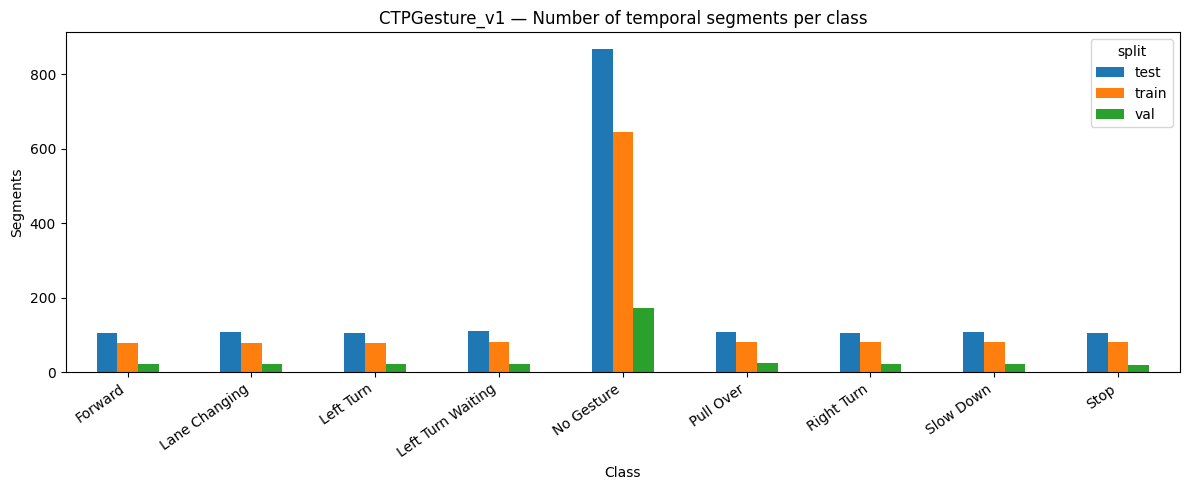

,split,label,class_name,frames,frame_share_%,mean_len,median_len,segments_lt_32f
0,train,0,No Gesture,30049,57.98,46.52,39.0,166
1,train,1,Stop,1750,3.38,21.88,21.0,76
2,train,2,Forward,3059,5.90,38.72,41.0,24
3,train,3,Left Turn,2659,5.13,33.66,31.0,44
4,train,4,Left Turn Waiting,2735,5.28,33.77,36.0,36
5,train,5,Right Turn,2755,5.32,34.44,31.0,45
6,train,6,Lane Changing,2537,4.90,32.11,31.0,49
7,train,7,Slow Down,3050,5.89,38.12,36.0,13
8,train,8,Pull Over,3230,6.23,40.38,36.0,11
9,val,0,No Gesture,8845,58.02,51.42,44.0,33


In [8]:
import matplotlib.pyplot as plt
import pandas as pd

# Segment count by class
pivot_segments = (
    stats_df
    .pivot(index="class_name", columns="split", values="segments")
    .fillna(0)
)

display(pivot_segments.astype(int))

ax = pivot_segments.plot(
    kind="bar",
    figsize=(12, 5),
)
ax.set_title("CTPGesture_v1 — Number of temporal segments per class")
ax.set_xlabel("Class")
ax.set_ylabel("Segments")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# Frame share by class
frame_stats = stats_df.copy()
frame_stats["frame_share_%"] = (
    frame_stats["frames"]
    / frame_stats.groupby("split")["frames"].transform("sum")
    * 100
)

display(
    frame_stats[
        ["split", "label", "class_name", "frames", "frame_share_%",
         "mean_len", "median_len", "segments_lt_32f"]
    ].round(2)
)


## CELL 7 — Patch VideoMamba for CTPGesture Direct-Decord + DDP + FP32

This patch is based on the previously working notebook and replaces the IPN Hand adapter with a CTPGesture adapter:

- read temporal segments directly from the original MP4 files;
- training = random temporal window;
- validation = center temporal window;
- test = multi-view temporal sampling;
- horizontal flip OFF;
- absolute learning rate;
- DDP optimization;
- FP32-safe checkpoint save/resume.


In [9]:
# ============================================================
# CELL 7 — Patch VideoMamba for CTPGesture + DDP + FP32 training
# ============================================================

import os
import py_compile
from pathlib import Path

REPO_DIR = '/kaggle/working/VideoMamba'
VIDEO_SM_DIR = Path(REPO_DIR) / 'videomamba' / 'video_sm'
DATASETS_DIR = VIDEO_SM_DIR / 'datasets'

# ============================================================
# Restore clean upstream files before applying patches
# ============================================================

!git -C /kaggle/working/VideoMamba checkout -- \
    videomamba/video_sm/datasets \
    videomamba/video_sm/run_class_finetuning.py \
    videomamba/video_sm/engines/engine_for_finetuning.py \
    videomamba/video_sm/utils.py


def replace_once(text, old, new, description):
    count = text.count(old)

    if count != 1:
        raise RuntimeError(
            f'{description}: expected 1 match, found {count}'
        )

    return text.replace(old, new, 1)


# ============================================================
# 1. CTPGesture dataset
#    Read annotated temporal segments directly from provider MP4 files
# ============================================================

ctp_dataset_path = DATASETS_DIR / 'ctp_gesture.py'

ctp_dataset_code = r'''import os

import numpy as np
import pandas as pd
from decord import VideoReader, cpu

from .kinetics import VideoClsDataset


class CTPGestureDataset(VideoClsDataset):
    """
    Read CTPGesture temporal segments directly from raw MP4 files.

    Annotation format:
        raw_path label t_start t_end uid

    t_start / t_end:
        1-based inclusive.
    """

    SEP = '|||'

    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)

        table = pd.read_csv(
            self.anno_path,
            sep=r'\s+',
            header=None,
            names=[
                'path',
                'label',
                't_start',
                't_end',
                'uid',
            ],
            engine='python',
        )

        if table.empty:
            raise RuntimeError(
                f'Empty annotation file: {self.anno_path}'
            )

        descriptors = []
        labels = []

        for row in table.itertuples(index=False):
            raw_path = str(row.path)
            label = int(row.label)
            if not 0 <= label <= 8:
                raise ValueError(
                    f'CTPGesture label outside [0, 8]: {label}'
                )
            t_start = int(row.t_start)
            t_end = int(row.t_end)
            uid = int(row.uid)

            stem = os.path.splitext(
                os.path.basename(raw_path)
            )[0]

            # Unique virtual sample name for VideoMamba merge().
            virtual_name = f'{stem}_seg{uid:05d}.mp4'

            descriptors.append(
                self.SEP.join([
                    raw_path,
                    str(t_start),
                    str(t_end),
                    '/' + virtual_name,
                ])
            )

            labels.append(label)

        self.dataset_samples = descriptors
        self.label_array = labels

        # Parent constructor builds test views before our
        # descriptors are available, so rebuild them.
        if self.mode == 'test':
            self.test_seg = []
            self.test_dataset = []
            self.test_label_array = []

            for ck in range(self.test_num_segment):
                for cp in range(self.test_num_crop):
                    for idx in range(len(self.label_array)):
                        self.test_label_array.append(
                            self.label_array[idx]
                        )

                        self.test_dataset.append(
                            self.dataset_samples[idx]
                        )

                        self.test_seg.append(
                            (ck, cp)
                        )

    def _parse_descriptor(self, sample):
        raw_path, t_start, t_end, virtual_name = (
            sample.split(self.SEP)
        )

        return (
            virtual_name,
            raw_path,
            int(t_start),
            int(t_end),
        )

    def loadvideo_decord(
        self,
        sample,
        sample_rate_scale=1,
        chunk_nb=0,
    ):
        try:
            (
                _,
                raw_path,
                t_start_1b,
                t_end_1b,
            ) = self._parse_descriptor(sample)

            fname = os.path.join(
                self.prefix,
                raw_path,
            )

            vr = VideoReader(
                fname,
                num_threads=1,
                ctx=cpu(0),
            )

            # CTPGesture:
            # 1-based inclusive
            # ->
            # 0-based [start, end_exclusive)
            seg_start = max(
                0,
                t_start_1b - 1,
            )

            seg_end = min(
                len(vr),
                t_end_1b,
            )

            seg_len = seg_end - seg_start

            if seg_len <= 0:
                return []

            converted_len = int(
                self.clip_len
                * self.frame_sample_rate
            )

            # ------------------------------------------------
            # Test
            # ------------------------------------------------

            if self.mode == 'test':
                if self.test_num_segment > 1:
                    temporal_step = max(
                        1.0
                        * (
                            seg_len
                            - converted_len
                        )
                        / (
                            self.test_num_segment
                            - 1
                        ),
                        0,
                    )
                else:
                    temporal_step = 0

                local_start = int(
                    chunk_nb * temporal_step
                )

                bound = min(
                    local_start
                    + converted_len,
                    seg_len,
                )

                local_indices = list(
                    range(
                        local_start,
                        bound,
                        self.frame_sample_rate,
                    )
                )

                if not local_indices:
                    local_indices = [0]

                while (
                    len(local_indices)
                    < self.clip_len
                ):
                    local_indices.append(
                        local_indices[-1]
                    )

                local_indices = (
                    local_indices[
                        :self.clip_len
                    ]
                )

                all_index = [
                    seg_start + x
                    for x in local_indices
                ]

                return (
                    vr.get_batch(
                        all_index
                    ).asnumpy()
                )

            # ------------------------------------------------
            # Train / validation
            # ------------------------------------------------

            if seg_len <= converted_len:
                n = max(
                    1,
                    seg_len
                    // self.frame_sample_rate,
                )

                index = np.linspace(
                    0,
                    seg_len,
                    num=n,
                )

                if n < self.clip_len:
                    index = np.concatenate(
                        (
                            index,
                            np.ones(
                                self.clip_len - n
                            )
                            * seg_len,
                        )
                    )

                index = np.clip(
                    index,
                    0,
                    seg_len - 1,
                ).astype(np.int64)

            else:
                if self.mode == 'validation':
                    # Deterministic center window.
                    str_idx = (
                        seg_len
                        - converted_len
                    ) // 2

                    end_idx = (
                        str_idx
                        + converted_len
                    )

                else:
                    # Random temporal window for training.
                    end_idx = np.random.randint(
                        converted_len,
                        seg_len,
                    )

                    str_idx = (
                        end_idx
                        - converted_len
                    )

                index = np.linspace(
                    str_idx,
                    end_idx,
                    num=self.clip_len,
                )

                index = np.clip(
                    index,
                    str_idx,
                    end_idx - 1,
                ).astype(np.int64)

            index = index[
                ::int(sample_rate_scale)
            ]

            all_index = (
                index + seg_start
            ).tolist()

            return (
                vr.get_batch(
                    all_index
                ).asnumpy()
            )

        except Exception as exc:
            print(
                'video cannot be loaded by decord:',
                sample,
                '|',
                repr(exc),
            )

            return []
'''

ctp_dataset_path.write_text(
    ctp_dataset_code,
    encoding='utf-8',
)

# Verify CSV separator immediately.
generated_ctp_source = (
    ctp_dataset_path.read_text(
        encoding='utf-8'
    )
)

if "sep=r'\\s+'," not in generated_ctp_source:
    raise RuntimeError(
        'Incorrect CTPGesture CSV separator.'
    )

print(
    '[OK] CTPGesture dataset source created '
    'with sep=r"\\s+".'
)


# ============================================================
# 2. build.py
#    Route data_set=CTPGesture -> CTPGestureDataset
# ============================================================

build_path = DATASETS_DIR / 'build.py'

build_code = build_path.read_text(
    encoding='utf-8'
)

build_code = replace_once(
    build_code,
    'from .kinetics import VideoClsDataset\n',
    (
        'from .kinetics import VideoClsDataset\n'
        'from .ctp_gesture import CTPGestureDataset\n'
    ),
    'build.py import CTPGestureDataset',
)

ctp_block = '''    elif args.data_set == 'CTPGesture':
        if is_train:
            mode = 'train'
            anno_path = os.path.join(
                args.data_path,
                'train.csv'
            )
        elif test_mode:
            mode = 'test'
            anno_path = os.path.join(
                args.data_path,
                'test.csv'
            )
        else:
            mode = 'validation'
            anno_path = os.path.join(
                args.data_path,
                'val.csv'
            )

        dataset = CTPGestureDataset(
            anno_path=anno_path,
            prefix=args.prefix,
            split=args.split,
            mode=mode,
            clip_len=args.num_frames,
            frame_sample_rate=args.sampling_rate,
            num_segment=1,
            test_num_segment=args.test_num_segment,
            test_num_crop=args.test_num_crop,
            num_crop=1 if not test_mode else args.test_num_crop,
            keep_aspect_ratio=True,
            crop_size=args.input_size,
            short_side_size=args.short_side_size,
            new_height=256,
            new_width=320,
            args=args,
        )

        nb_classes = args.nb_classes

'''

wrong_block = (
    "    else:\n"
    "        print(f'Wrong: {args.data_set}')\n"
    "        raise NotImplementedError()"
)

build_code = replace_once(
    build_code,
    wrong_block,
    ctp_block + wrong_block,
    'build.py CTPGesture block',
)

build_path.write_text(
    build_code,
    encoding='utf-8',
)


# ============================================================
# 3. Dataset compatibility patches
# ============================================================

kinetics_path = DATASETS_DIR / 'kinetics.py'

kinetics_code = kinetics_path.read_text(
    encoding='utf-8'
)

# Horizontal flip must be disabled because left/right
# are semantic gesture classes in CTPGesture.
kinetics_code = kinetics_code.replace(
    (
        "random_horizontal_flip=False "
        "if args.data_set == 'SSV2' else True"
    ),
    (
        "random_horizontal_flip=False "
        "if args.data_set in "
        "['SSV2', 'CTPGesture'] else True"
    ),
)

kinetics_path.write_text(
    kinetics_code,
    encoding='utf-8',
)

# NumPy 2 compatibility.
BAD_NUMPY_IMPORT = (
    'from numpy.lib.function_base import disp'
)

numpy_patched_files = []

for dataset_py in sorted(
    DATASETS_DIR.rglob('*.py')
):
    source = dataset_py.read_text(
        encoding='utf-8'
    )

    if BAD_NUMPY_IMPORT in source:
        source = source.replace(
            BAD_NUMPY_IMPORT,
            (
                '# NumPy 2 compatibility: '
                'removed unused disp import'
            ),
        )

        dataset_py.write_text(
            source,
            encoding='utf-8',
        )

        numpy_patched_files.append(
            str(dataset_py)
        )

remaining_bad_imports = []

for dataset_py in sorted(
    DATASETS_DIR.rglob('*.py')
):
    source = dataset_py.read_text(
        encoding='utf-8'
    )

    if BAD_NUMPY_IMPORT in source:
        remaining_bad_imports.append(
            str(dataset_py)
        )

if remaining_bad_imports:
    raise RuntimeError(
        'NumPy compatibility patch failed: '
        f'{remaining_bad_imports}'
    )

print(
    '[OK] NumPy 2 dataset compatibility patch applied.'
)


# ============================================================
# 4. run_class_finetuning.py
# ============================================================

run_path = (
    VIDEO_SM_DIR
    / 'run_class_finetuning.py'
)

run_code = run_path.read_text(
    encoding='utf-8'
)

# ------------------------------------------------------------
# Add CTPGesture dataset option
# ------------------------------------------------------------

run_code = replace_once(
    run_code,
    (
        "'mitv1_sparse', 'LVU', "
        "'COIN', 'Breakfast'"
    ),
    (
        "'mitv1_sparse', 'LVU', "
        "'COIN', 'Breakfast', "
        "'CTPGesture'"
    ),
    'dataset CLI choice',
)

# ------------------------------------------------------------
# Ensure sampler_test exists
# ------------------------------------------------------------

run_code = replace_once(
    run_code,
    (
        '        sampler_val = '
        'torch.utils.data.SequentialSampler'
        '(dataset_val)'
    ),
    (
        '        sampler_val = '
        'torch.utils.data.SequentialSampler'
        '(dataset_val)\n'
        '        sampler_test = '
        'torch.utils.data.SequentialSampler'
        '(dataset_test)'
    ),
    'sampler_test fallback',
)

# ------------------------------------------------------------
# Convert ImageNet pretrained weights for video input
# ------------------------------------------------------------

checkpoint_marker = (
    '        checkpoint_model = new_dict\n\n'
    '        # interpolate position embedding'
)

checkpoint_patch = '''        checkpoint_model = new_dict

        if (
            'patch_embed.proj.weight'
            in checkpoint_model
            and checkpoint_model[
                'patch_embed.proj.weight'
            ].ndim == 4
        ):
            checkpoint_model[
                'patch_embed.proj.weight'
            ] = checkpoint_model[
                'patch_embed.proj.weight'
            ].unsqueeze(2)

            print(
                'Inflated ImageNet Conv2d '
                'patch weights to Conv3d.'
            )

        if (
            'head.weight'
            in checkpoint_model
            and checkpoint_model[
                'head.weight'
            ].shape[0] != args.nb_classes
        ):
            checkpoint_model.pop(
                'head.weight',
                None,
            )

            checkpoint_model.pop(
                'head.bias',
                None,
            )

            print(
                'Removed the ImageNet '
                'classifier head.'
            )

        if (
            'temporal_pos_embedding'
            not in checkpoint_model
        ):
            original_temporal_size = (
                args.orig_t_size
                // model.patch_embed.tubelet_size
            )

            checkpoint_model[
                'temporal_pos_embedding'
            ] = (
                model.temporal_pos_embedding[
                    :,
                    :original_temporal_size
                ]
                .detach()
                .clone()
            )

            print(
                'Initialized missing temporal '
                'position embedding before '
                'interpolation.'
            )

        # interpolate position embedding'''

run_code = replace_once(
    run_code,
    checkpoint_marker,
    checkpoint_patch,
    'pretrained checkpoint conversion',
)

# ------------------------------------------------------------
# Keep the LR specified by the experiment configuration
# ------------------------------------------------------------

lr_scaling = '''    args.lr = args.lr * total_batch_size * args.num_sample / 256
    args.min_lr = args.min_lr * total_batch_size * args.num_sample / 256
    args.warmup_lr = args.warmup_lr * total_batch_size * args.num_sample / 256'''

run_code = replace_once(
    run_code,
    lr_scaling,
    (
        "    print("
        "'Using absolute learning-rate values; "
        "automatic linear batch-size scaling "
        "is disabled.'"
        ")"
    ),
    'absolute learning rate',
)

# ------------------------------------------------------------
# More efficient DDP
# ------------------------------------------------------------

run_code = replace_once(
    run_code,
    (
        '            model = '
        'torch.nn.parallel.DistributedDataParallel'
        '(model, device_ids=[args.gpu], '
        'find_unused_parameters=True)'
    ),
    (
        '            model = '
        'torch.nn.parallel.DistributedDataParallel'
        '(model, device_ids=[args.gpu], '
        'find_unused_parameters=False)'
    ),
    'DDP unused-parameter optimization',
)

# ------------------------------------------------------------
# DataLoader prefetch
# ------------------------------------------------------------

prefetch_marker = (
    '        persistent_workers=True\n'
    '    )'
)

prefetch_count = run_code.count(
    prefetch_marker
)

if prefetch_count == 0:
    raise RuntimeError(
        'Cannot locate DataLoader '
        'persistent_workers blocks.'
    )

run_code = run_code.replace(
    prefetch_marker,
    (
        '        persistent_workers=True,\n'
        '        prefetch_factor=2\n'
        '    )'
    ),
)

print(
    f'[OK] Added prefetch_factor=2 '
    f'to {prefetch_count} DataLoader block(s).'
)

# ------------------------------------------------------------
# Synchronize ranks before loading checkpoint-best
# ------------------------------------------------------------

post_train_marker = (
    "    preds_file = os.path.join("
    "args.output_dir, str(global_rank) + '.txt')\n"
    "    if args.test_best:"
)

post_train_pos = run_code.rfind(
    post_train_marker
)

if post_train_pos < 0:
    raise RuntimeError(
        'Cannot locate post-training '
        'test block.'
    )

run_code = (
    run_code[:post_train_pos]
    + (
        '    if args.distributed:\n'
        '        torch.distributed.barrier()\n'
    )
    + run_code[post_train_pos:]
)

run_path.write_text(
    run_code,
    encoding='utf-8',
)


# ============================================================
# 5. engine_for_finetuning.py
# ============================================================

engine_path = (
    VIDEO_SM_DIR
    / 'engines'
    / 'engine_for_finetuning.py'
)

engine_code = engine_path.read_text(
    encoding='utf-8'
)

# ------------------------------------------------------------
# Safe distributed loss gather
# ------------------------------------------------------------

old_loss = '''        loss_list = [torch.zeros_like(loss) for _ in range(dist.get_world_size())]
        dist.all_gather(loss_list, loss)
        loss_list = torch.tensor(loss_list)
        loss_list_isnan = torch.isnan(loss_list).any()
        loss_list_isinf = torch.isinf(loss_list).any()'''

new_loss = '''        if dist.is_available() and dist.is_initialized():
            loss_list = [
                torch.zeros_like(loss)
                for _ in range(
                    dist.get_world_size()
                )
            ]

            dist.all_gather(
                loss_list,
                loss,
            )

            loss_list = torch.stack(
                loss_list
            )

            loss_list_isnan = (
                torch.isnan(loss_list).any()
            )

            loss_list_isinf = (
                torch.isinf(loss_list).any()
            )

        else:
            loss_list_isnan = (
                torch.isnan(loss).any()
            )

            loss_list_isinf = (
                torch.isinf(loss).any()
            )'''

engine_code = replace_once(
    engine_code,
    old_loss,
    new_loss,
    'safe distributed loss gather',
)

# ------------------------------------------------------------
# Remove unnecessary forced synchronization every batch
# ------------------------------------------------------------

engine_code = engine_code.replace(
    '        torch.cuda.synchronize()\n',
    '',
)

# ------------------------------------------------------------
# FP32 gradient path
# ------------------------------------------------------------

old_grad = '''            else:
                loss /= update_freq
                loss.backward()
                if (data_iter_step + 1) % update_freq == 0:
                    if max_norm is not None:
                        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm)
                    optimizer.step()
                    optimizer.zero_grad()
                    if model_ema is not None:
                        model_ema.update(model)
                loss_scale_value = 0'''

new_grad = '''            else:
                loss /= update_freq
                loss.backward()

                grad_norm = None

                if (
                    (data_iter_step + 1)
                    % update_freq
                    == 0
                ):
                    if max_norm is not None:
                        grad_norm = (
                            torch.nn.utils
                            .clip_grad_norm_(
                                model.parameters(),
                                max_norm,
                            )
                        )

                    optimizer.step()
                    optimizer.zero_grad()

                    if model_ema is not None:
                        model_ema.update(
                            model
                        )

                loss_scale_value = 0'''

engine_code = replace_once(
    engine_code,
    old_grad,
    new_grad,
    'FP32 grad_norm path',
)

# ------------------------------------------------------------
# tqdm progress bar on rank 0
# ------------------------------------------------------------

if (
    'from tqdm.auto import tqdm'
    not in engine_code
):
    engine_code = engine_code.replace(
        'import torch\n',
        (
            'import torch\n'
            'from tqdm.auto import tqdm\n'
        ),
        1,
    )

old_loop = (
    '    for data_iter_step, '
    '(samples, targets, _, _) '
    'in enumerate('
    'metric_logger.log_every('
    'data_loader, print_freq, header'
    ')):\n'
)

new_loop = '''    train_iter = data_loader
    progress = None

    if utils.is_main_process():
        progress = tqdm(
            data_loader,
            total=len(data_loader),
            desc=f"Epoch {epoch + 1}",
            unit="batch",
            dynamic_ncols=True,
            leave=False,
        )

        train_iter = progress

    for data_iter_step, (
        samples,
        targets,
        _,
        _,
    ) in enumerate(train_iter):
'''

engine_code = replace_once(
    engine_code,
    old_loop,
    new_loop,
    'training tqdm',
)

metric_marker = (
    '        metric_logger.update('
    'grad_norm=grad_norm)\n'
)

metric_patch = '''        metric_logger.update(
            grad_norm=grad_norm
        )

        if progress is not None:
            running_loss = (
                metric_logger
                .meters["loss"]
                .global_avg
            )

            running_acc = (
                metric_logger
                .meters["class_acc"]
                .global_avg
                * 100.0
            )

            progress.set_postfix(
                {
                    "loss": (
                        f"{running_loss:.4f}"
                    ),
                    "acc": (
                        f"{running_acc:.1f}%"
                    ),
                    "lr": (
                        f"{max_lr:.2e}"
                    ),
                },
                refresh=False,
            )
'''

engine_code = replace_once(
    engine_code,
    metric_marker,
    metric_patch,
    'training progress metrics',
)

# ------------------------------------------------------------
# Close tqdm only inside train_one_epoch()
# ------------------------------------------------------------

sync_marker = '''    # gather the stats from all processes
    metric_logger.synchronize_between_processes()
'''

sync_patch = '''    if progress is not None:
        progress.close()

    # gather the stats from all processes
    metric_logger.synchronize_between_processes()
'''

train_start = engine_code.find(
    'def train_one_epoch('
)

validation_start = engine_code.find(
    (
        '@torch.no_grad()\n'
        'def validation_one_epoch'
    ),
    train_start,
)

if train_start < 0:
    raise RuntimeError(
        'Cannot locate train_one_epoch().'
    )

if validation_start < 0:
    raise RuntimeError(
        'Cannot locate validation_one_epoch().'
    )

train_section = engine_code[
    train_start:validation_start
]

sync_count = train_section.count(
    sync_marker
)

if sync_count != 1:
    raise RuntimeError(
        'close tqdm in train_one_epoch: '
        f'expected 1 match, found {sync_count}'
    )

train_section = train_section.replace(
    sync_marker,
    sync_patch,
    1,
)

engine_code = (
    engine_code[:train_start]
    + train_section
    + engine_code[validation_start:]
)

# ------------------------------------------------------------
# Compact validation logging + visible final-test progress
# ------------------------------------------------------------

# Remove train_one_epoch()'s verbose final summary.
engine_code = engine_code.replace(
    (
        '    print("Averaged stats:", '
        'metric_logger)\n'
    ),
    '',
)

# ------------------------------------------------------------
# Validation: silent
# run_class_finetuning.py will print one compact epoch summary.
# ------------------------------------------------------------

validation_start = engine_code.find(
    '@torch.no_grad()\n'
    'def validation_one_epoch'
)

final_test_start = engine_code.find(
    '@torch.no_grad()\n'
    'def final_test',
    validation_start,
)

if validation_start < 0 or final_test_start < 0:
    raise RuntimeError(
        'Cannot locate validation/final_test sections.'
    )

validation_section = engine_code[
    validation_start:final_test_start
]

validation_section = replace_once(
    validation_section,
    (
        '    for batch in '
        'metric_logger.log_every('
        'data_loader, 10, header):\n'
    ),
    '    for batch in data_loader:\n',
    'silent validation loop',
)

validation_print = '''    print('* Acc@1 {top1.global_avg:.3f} Acc@5 {top5.global_avg:.3f} loss {losses.global_avg:.3f}'
          .format(top1=metric_logger.acc1, top5=metric_logger.acc5, losses=metric_logger.loss))
'''

validation_section = replace_once(
    validation_section,
    validation_print,
    '',
    'silent validation summary',
)

engine_code = (
    engine_code[:validation_start]
    + validation_section
    + engine_code[final_test_start:]
)

# ------------------------------------------------------------
# Final test: tqdm progress on rank 0 only
# ------------------------------------------------------------

final_test_start = engine_code.find(
    '@torch.no_grad()\n'
    'def final_test'
)

merge_start = engine_code.find(
    '\ndef merge(',
    final_test_start,
)

if final_test_start < 0 or merge_start < 0:
    raise RuntimeError(
        'Cannot isolate final_test().'
    )

final_test_section = engine_code[
    final_test_start:merge_start
]

old_test_loop = (
    '    for batch in '
    'metric_logger.log_every('
    'data_loader, 10, header):\n'
)

new_test_loop = '''    test_iter = data_loader
    test_progress = None

    if utils.is_main_process():
        test_progress = tqdm(
            data_loader,
            total=len(data_loader),
            desc="Test FP32" if no_amp else "Test",
            unit="batch",
            dynamic_ncols=True,
            leave=True,
        )
        test_iter = test_progress

    for batch in test_iter:
'''

final_test_section = replace_once(
    final_test_section,
    old_test_loop,
    new_test_loop,
    'final-test tqdm',
)

test_metric_marker = '''        metric_logger.meters['acc5'].update(acc5.item(), n=batch_size)

    if not os.path.exists(file):
'''

test_metric_patch = '''        metric_logger.meters['acc5'].update(acc5.item(), n=batch_size)

        if test_progress is not None:
            test_progress.set_postfix(
                {
                    "loss": f"{metric_logger.meters['loss'].global_avg:.4f}",
                    "acc1": f"{metric_logger.meters['acc1'].global_avg:.1f}%",
                    "acc5": f"{metric_logger.meters['acc5'].global_avg:.1f}%",
                },
                refresh=False,
            )

    if test_progress is not None:
        test_progress.close()

    if not os.path.exists(file):
'''

final_test_section = replace_once(
    final_test_section,
    test_metric_marker,
    test_metric_patch,
    'final-test progress metrics',
)

engine_code = (
    engine_code[:final_test_start]
    + final_test_section
    + engine_code[merge_start:]
)

# ------------------------------------------------------------
# Verify logging behavior
# ------------------------------------------------------------

validation_start = engine_code.find(
    '@torch.no_grad()\n'
    'def validation_one_epoch'
)

final_test_start = engine_code.find(
    '@torch.no_grad()\n'
    'def final_test',
    validation_start,
)

validation_section = engine_code[
    validation_start:final_test_start
]

if 'metric_logger.log_every' in validation_section:
    raise RuntimeError(
        'Validation progress logging was not disabled.'
    )

if 'test_progress = tqdm(' not in engine_code:
    raise RuntimeError(
        'Final-test tqdm patch missing.'
    )

if 'desc="Test FP32" if no_amp else "Test"' not in engine_code:
    raise RuntimeError(
        'Final-test FP32 progress label missing.'
    )

engine_path.write_text(
    engine_code,
    encoding='utf-8',
)

print('[OK] Validation logging compacted.')
print('[OK] Final-test tqdm progress enabled on rank 0.')


# ============================================================
# 6. Compact one-line epoch summary
# ============================================================

run_code = run_path.read_text(
    encoding='utf-8'
)

run_code = run_code.replace(
    '''            print(f"[{timestep}] Accuracy of the network on the {len(dataset_val)} val videos: {test_stats['acc1']:.1f}%")
''',
    '',
)

run_code = run_code.replace(
    (
        "            print("
        "f'Max accuracy: "
        "{max_accuracy:.2f}%'"
        ")\n"
    ),
    '',
)

best_save = '''                    utils.save_model(
                        args=args, model=model, model_without_ddp=model_without_ddp, optimizer=optimizer,
                        loss_scaler=loss_scaler, epoch=epoch, model_name='best', model_ema=model_ema)

            if log_writer is not None:
'''

summary = '''                    utils.save_model(
                        args=args, model=model, model_without_ddp=model_without_ddp, optimizer=optimizer,
                        loss_scaler=loss_scaler, epoch=epoch, model_name='best', model_ema=model_ema)

            if utils.is_main_process():
                train_loss = train_stats.get(
                    "loss",
                    float("nan"),
                )

                train_acc = (
                    train_stats.get(
                        "class_acc",
                        float("nan"),
                    )
                    * 100.0
                )

                val_loss = test_stats.get(
                    "loss",
                    float("nan"),
                )

                val_acc = test_stats.get(
                    "acc1",
                    float("nan"),
                )

                current_lr = train_stats.get(
                    "lr",
                    float("nan"),
                )

                print(
                    f"Epoch "
                    f"{epoch + 1:02d}/"
                    f"{args.epochs:02d} | "
                    f"train_loss="
                    f"{train_loss:.4f} | "
                    f"train_acc="
                    f"{train_acc:.1f}% | "
                    f"val_loss="
                    f"{val_loss:.4f} | "
                    f"val_acc="
                    f"{val_acc:.1f}% | "
                    f"best="
                    f"{max_accuracy:.1f}% | "
                    f"lr="
                    f"{current_lr:.2e}"
                )

            if log_writer is not None:
'''

run_code = replace_once(
    run_code,
    best_save,
    summary,
    'epoch summary',
)

run_path.write_text(
    run_code,
    encoding='utf-8',
)


# ============================================================
# 7. FP32-safe checkpoint save / resume
# ============================================================

utils_path = VIDEO_SM_DIR / 'utils.py'

utils_code = utils_path.read_text(
    encoding='utf-8'
)

# ------------------------------------------------------------
# Save:
# loss_scaler == "none" under --no_amp.
# Do NOT call "none".state_dict().
# ------------------------------------------------------------

utils_code = replace_once(
    utils_code,
    (
        "                'scaler': "
        "loss_scaler.state_dict(),"
    ),
    (
        "                'scaler': "
        "loss_scaler.state_dict() "
        "if hasattr(loss_scaler, "
        "'state_dict') else None,"
    ),
    'FP32 checkpoint save',
)

# ------------------------------------------------------------
# Resume:
# only restore scaler when an actual AMP scaler exists.
# ------------------------------------------------------------

old_scaler_resume = '''                if 'scaler' in checkpoint:
                    loss_scaler.load_state_dict(checkpoint['scaler'])'''

new_scaler_resume = '''                if (
                    checkpoint.get(
                        'scaler'
                    ) is not None
                    and hasattr(
                        loss_scaler,
                        'load_state_dict'
                    )
                ):
                    loss_scaler.load_state_dict(
                        checkpoint['scaler']
                    )'''

utils_code = replace_once(
    utils_code,
    old_scaler_resume,
    new_scaler_resume,
    'FP32 checkpoint resume',
)

# ------------------------------------------------------------
# PyTorch 2.x compatible checkpoint loading
# ------------------------------------------------------------

utils_code = replace_once(
    utils_code,
    (
        "            checkpoint = "
        "torch.load("
        "args.resume, "
        "map_location='cpu')"
    ),
    '''            try:
                checkpoint = torch.load(
                    args.resume,
                    map_location='cpu',
                    weights_only=False,
                )
            except TypeError:
                checkpoint = torch.load(
                    args.resume,
                    map_location='cpu',
                )''',
    'robust torch.load',
)

# ------------------------------------------------------------
# Static verification
# ------------------------------------------------------------

if (
    "hasattr(loss_scaler, 'state_dict')"
    not in utils_code
):
    raise RuntimeError(
        'FP32 checkpoint save patch missing.'
    )

if (
    "checkpoint.get("
    not in utils_code
):
    raise RuntimeError(
        'FP32 checkpoint resume patch missing.'
    )

if (
    "'load_state_dict'"
    not in utils_code
):
    raise RuntimeError(
        'FP32 checkpoint resume guard missing.'
    )

utils_path.write_text(
    utils_code,
    encoding='utf-8',
)

print(
    '[OK] FP32 checkpoint save/resume '
    'patch applied.'
)


# ============================================================
# 8. Syntax checks
# ============================================================

syntax_paths = [
    ctp_dataset_path,
    build_path,
    kinetics_path,
    run_path,
    engine_path,
    utils_path,
]

for path in syntax_paths:
    py_compile.compile(
        str(path),
        doraise=True,
    )

    print(
        '[OK] Syntax:',
        path,
    )


# ============================================================
# 9. Final verification
# ============================================================

if (
    "sep=r'\\s+',"
    not in ctp_dataset_path.read_text(
        encoding='utf-8'
    )
):
    raise RuntimeError(
        'Final CSV separator verification failed.'
    )

remaining_numpy_issues = []

for dataset_py in DATASETS_DIR.rglob(
    '*.py'
):
    source = dataset_py.read_text(
        encoding='utf-8'
    )

    if BAD_NUMPY_IMPORT in source:
        remaining_numpy_issues.append(
            str(dataset_py)
        )

if remaining_numpy_issues:
    raise RuntimeError(
        'Obsolete NumPy imports remain: '
        f'{remaining_numpy_issues}'
    )

print('=' * 70)
print('CELL 7 PATCH SUMMARY')
print('=' * 70)
print('CTPGesture direct Decord       : OK')
print('CSV separator                : OK')
print('NumPy 2 compatibility        : OK')
print('Horizontal flip disabled     : OK')
print('Pretrained weight conversion : OK')
print('DDP optimization             : OK')
print('FP32 gradient path           : OK')
print('FP32 checkpoint save         : OK')
print('FP32 checkpoint resume       : OK')
print('Final-test tqdm progress      : OK')
print('PyTorch checkpoint loading   : OK')
print('Syntax checks                : OK')
print('=' * 70)

[OK] CTPGesture dataset source created with sep=r"\s+".
[OK] NumPy 2 dataset compatibility patch applied.
[OK] Added prefetch_factor=2 to 1 DataLoader block(s).
[OK] Validation logging compacted.
[OK] Final-test tqdm progress enabled on rank 0.
[OK] FP32 checkpoint save/resume patch applied.
[OK] Syntax: /kaggle/working/VideoMamba/videomamba/video_sm/datasets/ctp_gesture.py
[OK] Syntax: /kaggle/working/VideoMamba/videomamba/video_sm/datasets/build.py
[OK] Syntax: /kaggle/working/VideoMamba/videomamba/video_sm/datasets/kinetics.py
[OK] Syntax: /kaggle/working/VideoMamba/videomamba/video_sm/run_class_finetuning.py
[OK] Syntax: /kaggle/working/VideoMamba/videomamba/video_sm/engines/engine_for_finetuning.py
[OK] Syntax: /kaggle/working/VideoMamba/videomamba/video_sm/utils.py
CELL 7 PATCH SUMMARY
CTPGesture direct Decord       : OK
CSV separator                : OK
NumPy 2 compatibility        : OK
Horizontal flip disabled     : OK
Pretrained weight conversion : OK
DDP optimization         

## CELL 8 — Download and Verify the Pretrained VideoMamba-Tiny Checkpoint


In [10]:
import os
import torch

CHECKPOINT_PATH.parent.mkdir(parents=True, exist_ok=True)

if (
    not CHECKPOINT_PATH.is_file()
    or CHECKPOINT_PATH.stat().st_size < 10_000_000
):
    !wget -q --show-progress \
        'https://huggingface.co/OpenGVLab/VideoMamba/resolve/main/videomamba_t16_in1k_res224.pth' \
        -O {CHECKPOINT_PATH}
else:
    print("[CACHE] Reusing pretrained checkpoint:", CHECKPOINT_PATH)

if not CHECKPOINT_PATH.is_file():
    raise FileNotFoundError(CHECKPOINT_PATH)

if CHECKPOINT_PATH.stat().st_size < 10_000_000:
    raise RuntimeError("Checkpoint is unexpectedly small.")

try:
    ckpt = torch.load(
        CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=False,
    )
except TypeError:
    ckpt = torch.load(
        CHECKPOINT_PATH,
        map_location="cpu",
    )

if "model" not in ckpt:
    raise KeyError('Expected key "model" in pretrained checkpoint.')

if not all(
    torch.isfinite(v).all()
    for v in ckpt["model"].values()
    if torch.is_tensor(v)
):
    raise ValueError("Pretrained checkpoint contains non-finite tensors.")

print("[OK] Pretrained checkpoint verified:", CHECKPOINT_PATH)
del ckpt


          /kaggle/w   0%[                    ]       0  --.-KB/s               

         /kaggle/wo   0%[                    ]   1.35K  3.27KB/s               

        /kaggle/wor  81%[===============>    ]  22.32M  36.5MB/s               

/kaggle/working/che 100%[===================>]  27.41M  42.1MB/s    in 0.7s    


[OK] Pretrained checkpoint verified: /kaggle/working/checkpoints/videomamba_t16_in1k.pth


## CELL 9 — Dataset Loader Sanity Check Before Training


In [11]:
# ============================================================
# CELL 9 — Dataset Loader Sanity Check Before Training
# ============================================================

import sys
from pathlib import Path
from types import SimpleNamespace

import torch


# ============================================================
# 1. Resolve VideoMamba source path robustly
# ============================================================

REPO_DIR = Path(REPO_DIR)

VIDEO_SM_DIR = (
    REPO_DIR
    / "videomamba"
    / "video_sm"
)

print("[INFO] REPO_DIR:")
print("      ", REPO_DIR)

print("[INFO] VIDEO_SM_DIR:")
print("      ", VIDEO_SM_DIR)


if not REPO_DIR.exists():
    raise RuntimeError(
        f"VideoMamba repository does not exist:\n{REPO_DIR}"
    )


if not VIDEO_SM_DIR.exists():
    raise RuntimeError(
        f"VideoMamba video_sm directory does not exist:\n"
        f"{VIDEO_SM_DIR}"
    )


# Add VideoMamba source to Python import path
if str(VIDEO_SM_DIR) not in sys.path:
    sys.path.insert(
        0,
        str(VIDEO_SM_DIR)
    )


print(
    "[OK] VideoMamba source path is available."
)


# ============================================================
# 2. Verify generated CTPGesture dataset loader
# ============================================================

CTP_LOADER_PATH = (
    VIDEO_SM_DIR
    / "datasets"
    / "ctp_gesture.py"
)


if not CTP_LOADER_PATH.exists():
    raise RuntimeError(
        "CTPGesture loader was not generated by Cell 7:\n"
        f"{CTP_LOADER_PATH}"
    )


print(
    "[OK] CTPGesture loader found:"
)

print(
    "     ",
    CTP_LOADER_PATH
)


# ============================================================
# 3. Verify annotation files
# ============================================================

required_annotation_files = {
    "train": ANNOTATION_ROOT / "train.csv",
    "val": ANNOTATION_ROOT / "val.csv",
    "test": ANNOTATION_ROOT / "test.csv",
}


for split_name, path in required_annotation_files.items():

    if not path.exists():
        raise RuntimeError(
            f"Missing {split_name} annotation file:\n{path}"
        )

    if path.stat().st_size == 0:
        raise RuntimeError(
            f"Empty {split_name} annotation file:\n{path}"
        )

    print(
        f"[OK] {split_name:5s} annotation:",
        path
    )


# ============================================================
# 4. Import custom CTPGesture loader
# ============================================================

from datasets.ctp_gesture import CTPGestureDataset


print(
    "[OK] CTPGestureDataset imported successfully."
)


# ============================================================
# 5. Dataset arguments
# ============================================================

dataset_args = SimpleNamespace(

    # Random erasing
    reprob=0.25,
    remode="pixel",
    recount=1,

    # RandAugment
    aa="rand-m5-n2-mstd0.25-inc1",

    # Resize interpolation
    train_interpolation="bicubic",

    # Dataset name
    data_set="CTPGesture",

    # No repeated augmentation
    num_sample=1,
)


# ============================================================
# 6. Dataset factory
# ============================================================

def make_dataset(
    split_name,
    mode,
):

    annotation_path = (
        ANNOTATION_ROOT
        / f"{split_name}.csv"
    )

    dataset = CTPGestureDataset(

        anno_path=str(
            annotation_path
        ),

        # Raw absolute MP4 paths are already stored
        # inside the generated annotation CSV.
        prefix="",

        split=" ",

        mode=mode,

        # VideoMamba-Tiny input configuration
        clip_len=NUM_FRAMES,
        frame_sample_rate=SAMPLING_RATE,
        num_segment=1,

        # Multi-view test configuration
        test_num_segment=TEST_NUM_SEGMENT,
        test_num_crop=TEST_NUM_CROP,

        num_crop=(
            TEST_NUM_CROP
            if mode == "test"
            else 1
        ),

        keep_aspect_ratio=True,

        crop_size=INPUT_SIZE,

        short_side_size=SHORT_SIDE_SIZE,

        new_height=256,
        new_width=320,

        args=dataset_args,
    )

    return dataset


# ============================================================
# 7. Build datasets
# ============================================================

print("\n" + "=" * 72)
print("BUILDING DATASETS")
print("=" * 72)


train_ds = make_dataset(
    "train",
    "train",
)


val_ds = make_dataset(
    "val",
    "validation",
)


test_ds = make_dataset(
    "test",
    "test",
)


print(
    "[INFO] Train dataset samples:",
    len(train_ds)
)

print(
    "[INFO] Validation dataset samples:",
    len(val_ds)
)

print(
    "[INFO] Test dataset views:",
    len(test_ds)
)


# ============================================================
# 8. Expected tensor shape
# ============================================================

expected_shape = (
    3,
    NUM_FRAMES,
    INPUT_SIZE,
    INPUT_SIZE,
)


print(
    "[INFO] Expected tensor shape:",
    expected_shape
)


# ============================================================
# 9. Train sample sanity check
# ============================================================

print("\n" + "=" * 72)
print("TRAIN SAMPLE CHECK")
print("=" * 72)


train_output = train_ds[0]


if len(train_output) != 4:
    raise RuntimeError(
        "Unexpected train dataset output format.\n"
        f"Expected 4 elements, got {len(train_output)}"
    )


(
    train_tensor,
    train_label,
    train_index,
    train_extra,
) = train_output


print(
    "[INFO] Train tensor:",
    tuple(train_tensor.shape),
    train_tensor.dtype
)

print(
    "[INFO] Train label:",
    int(train_label),
    CLASS_NAMES[int(train_label)]
)

print(
    "[INFO] Train index:",
    train_index
)


if tuple(train_tensor.shape) != expected_shape:
    raise RuntimeError(
        "Unexpected train tensor shape.\n"
        f"Expected: {expected_shape}\n"
        f"Found:    {tuple(train_tensor.shape)}"
    )


if not torch.isfinite(train_tensor).all():
    raise RuntimeError(
        "Train tensor contains NaN or Inf."
    )


if not (
    0 <= int(train_label) < NUM_CLASSES
):
    raise RuntimeError(
        f"Invalid train label: {train_label}"
    )


print(
    "[OK] Train loader sanity check passed."
)


# ============================================================
# 10. Validation sample sanity check
# ============================================================

print("\n" + "=" * 72)
print("VALIDATION SAMPLE CHECK")
print("=" * 72)


val_output = val_ds[0]


if len(val_output) != 3:
    raise RuntimeError(
        "Unexpected validation dataset output format.\n"
        f"Expected 3 elements, got {len(val_output)}"
    )


(
    val_tensor,
    val_label,
    val_name,
) = val_output


print(
    "[INFO] Validation tensor:",
    tuple(val_tensor.shape),
    val_tensor.dtype
)

print(
    "[INFO] Validation label:",
    int(val_label),
    CLASS_NAMES[int(val_label)]
)

print(
    "[INFO] Validation sample ID:",
    val_name
)


if tuple(val_tensor.shape) != expected_shape:
    raise RuntimeError(
        "Unexpected validation tensor shape.\n"
        f"Expected: {expected_shape}\n"
        f"Found:    {tuple(val_tensor.shape)}"
    )


if not torch.isfinite(val_tensor).all():
    raise RuntimeError(
        "Validation tensor contains NaN or Inf."
    )


if not (
    0 <= int(val_label) < NUM_CLASSES
):
    raise RuntimeError(
        f"Invalid validation label: {val_label}"
    )


print(
    "[OK] Validation loader sanity check passed."
)


# ============================================================
# 11. Test sample sanity check
# ============================================================

print("\n" + "=" * 72)
print("TEST SAMPLE CHECK")
print("=" * 72)


test_output = test_ds[0]


if len(test_output) != 5:
    raise RuntimeError(
        "Unexpected test dataset output format.\n"
        f"Expected 5 elements, got {len(test_output)}"
    )


(
    test_tensor,
    test_label,
    test_name,
    chunk_nb,
    split_nb,
) = test_output


print(
    "[INFO] Test tensor:",
    tuple(test_tensor.shape),
    test_tensor.dtype
)

print(
    "[INFO] Test label:",
    int(test_label),
    CLASS_NAMES[int(test_label)]
)

print(
    "[INFO] Test sample ID:",
    test_name
)

print(
    "[INFO] Temporal view:",
    chunk_nb
)

print(
    "[INFO] Spatial crop:",
    split_nb
)


if tuple(test_tensor.shape) != expected_shape:
    raise RuntimeError(
        "Unexpected test tensor shape.\n"
        f"Expected: {expected_shape}\n"
        f"Found:    {tuple(test_tensor.shape)}"
    )


if not torch.isfinite(test_tensor).all():
    raise RuntimeError(
        "Test tensor contains NaN or Inf."
    )


if not (
    0 <= int(test_label) < NUM_CLASSES
):
    raise RuntimeError(
        f"Invalid test label: {test_label}"
    )


print(
    "[OK] Test loader sanity check passed."
)


# ============================================================
# 12. Verify 12-view test expansion
# ============================================================

num_test_segments = sum(
    1
    for _ in open(
        ANNOTATION_ROOT / "test.csv",
        "r",
        encoding="utf-8",
    )
)


expected_test_views = (
    num_test_segments
    * TEST_NUM_SEGMENT
    * TEST_NUM_CROP
)


print("\n" + "=" * 72)
print("TEST VIEW CHECK")
print("=" * 72)


print(
    "[INFO] Test temporal segments:",
    num_test_segments
)

print(
    "[INFO] Temporal views per segment:",
    TEST_NUM_SEGMENT
)

print(
    "[INFO] Spatial crops per temporal view:",
    TEST_NUM_CROP
)

print(
    "[INFO] Views per segment:",
    TEST_NUM_SEGMENT
    * TEST_NUM_CROP
)

print(
    "[INFO] Expected total test views:",
    expected_test_views
)

print(
    "[INFO] Actual total test views:",
    len(test_ds)
)


if len(test_ds) != expected_test_views:
    raise RuntimeError(
        "Unexpected number of test views.\n"
        f"Expected: {expected_test_views}\n"
        f"Found:    {len(test_ds)}"
    )


print(
    "[OK] Test multi-view expansion verified."
)


# ============================================================
# FINAL REPORT
# ============================================================

print("\n" + "=" * 72)
print("DATASET LOADER SANITY CHECK COMPLETE")
print("=" * 72)


print(
    "[OK] Train loader      : PASS"
)

print(
    "[OK] Validation loader : PASS"
)

print(
    "[OK] Test loader       : PASS"
)

print(
    "[OK] Tensor shape      :",
    expected_shape
)

print(
    "[OK] Test views/sample :",
    TEST_NUM_SEGMENT
    * TEST_NUM_CROP
)


print(
    "\n[READY] Dataset loader is ready for VideoMamba training."
)

[INFO] REPO_DIR:
       /kaggle/working/VideoMamba
[INFO] VIDEO_SM_DIR:
       /kaggle/working/VideoMamba/videomamba/video_sm
[OK] VideoMamba source path is available.
[OK] CTPGesture loader found:
      /kaggle/working/VideoMamba/videomamba/video_sm/datasets/ctp_gesture.py
[OK] train annotation: /kaggle/working/ctpgesture_annotations/train.csv
[OK] val   annotation: /kaggle/working/ctpgesture_annotations/val.csv
[OK] test  annotation: /kaggle/working/ctpgesture_annotations/test.csv


[OK] CTPGestureDataset imported successfully.

BUILDING DATASETS
[INFO] Train dataset samples: 1284
[INFO] Validation dataset samples: 342
[INFO] Test dataset views: 20736
[INFO] Expected tensor shape: (3, 16, 224, 224)

TRAIN SAMPLE CHECK


[INFO] Train tensor: (3, 16, 224, 224) torch.float32
[INFO] Train label: 0 No Gesture
[INFO] Train index: 0
[OK] Train loader sanity check passed.

VALIDATION SAMPLE CHECK


[INFO] Validation tensor: (3, 16, 224, 224) torch.float32
[INFO] Validation label: 0 No Gesture
[INFO] Validation sample ID: 003_seg00000
[OK] Validation loader sanity check passed.

TEST SAMPLE CHECK


[INFO] Test tensor: (3, 16, 224, 224) torch.float32
[INFO] Test label: 0 No Gesture
[INFO] Test sample ID: 002_seg00000
[INFO] Temporal view: 0
[INFO] Spatial crop: 0
[OK] Test loader sanity check passed.

TEST VIEW CHECK
[INFO] Test temporal segments: 1728
[INFO] Temporal views per segment: 4
[INFO] Spatial crops per temporal view: 3
[INFO] Views per segment: 12
[INFO] Expected total test views: 20736
[INFO] Actual total test views: 20736
[OK] Test multi-view expansion verified.

DATASET LOADER SANITY CHECK COMPLETE
[OK] Train loader      : PASS
[OK] Validation loader : PASS
[OK] Test loader       : PASS
[OK] Tensor shape      : (3, 16, 224, 224)
[OK] Test views/sample : 12

[READY] Dataset loader is ready for VideoMamba training.


## CELL 10 — Fine-Tune VideoMamba-Tiny


In [12]:
import os
import py_compile
from pathlib import Path

VIDEO_SM_DIR = REPO_DIR / "videomamba" / "video_sm"
DATASETS_DIR = VIDEO_SM_DIR / "datasets"

required_files = [
    DATASETS_DIR / "ctp_gesture.py",
    DATASETS_DIR / "build.py",
    DATASETS_DIR / "kinetics.py",
    VIDEO_SM_DIR / "run_class_finetuning.py",
    VIDEO_SM_DIR / "engines" / "engine_for_finetuning.py",
    VIDEO_SM_DIR / "utils.py",
]

for p in required_files:
    if not p.is_file():
        raise FileNotFoundError(p)
    py_compile.compile(str(p), doraise=True)

for name in ["train.csv", "val.csv", "test.csv"]:
    p = ANNOTATION_ROOT / name
    if not p.is_file() or p.stat().st_size == 0:
        raise FileNotFoundError(p)

if not CHECKPOINT_PATH.is_file():
    raise FileNotFoundError(CHECKPOINT_PATH)

print("=" * 72)
print("FINAL TRAINING CONFIGURATION")
print("=" * 72)
print("Dataset                : CTPGesture_v1")
print("Classes                : 9 (0..8)")
print("Train videos           :", TRAIN_IDS)
print("Val videos             :", VAL_IDS)
print("Test videos            :", TEST_IDS)
print("Model                  :", MODEL_NAME)
print("Frames                 :", NUM_FRAMES)
print("Sampling rate          :", SAMPLING_RATE)
print("Resolution             :", f"{INPUT_SIZE}x{INPUT_SIZE}")
print("Precision              : FP32")
print("GPUs                   :", DDP_GPUS)
print("Batch / GPU            :", TRAIN_BATCH_SIZE)
print("Update frequency       :", UPDATE_FREQ)
print("Effective batch        :", EFFECTIVE_BATCH_SIZE)
print("Optimizer              : AdamW")
print("LR                     :", LR)
print("Weight decay           :", WEIGHT_DECAY)
print("Layer decay            :", LAYER_DECAY)
print("Warmup epochs          :", WARMUP_EPOCHS)
print("Epochs                 :", EPOCHS)
print("Horizontal flip        : OFF")
print("Mixup / CutMix         : OFF / OFF")
print("Final test views       :", TEST_NUM_SEGMENT * TEST_NUM_CROP)
print("Output                 :", OUTPUT_DIR)
print("=" * 72)

%cd /kaggle/working/VideoMamba/videomamba/video_sm

!PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True \
torchrun \
    --standalone \
    --nproc_per_node={DDP_GPUS} \
    run_class_finetuning.py \
    --model {MODEL_NAME} \
    --finetune {CHECKPOINT_PATH} \
    --data_set CTPGesture \
    --data_path {ANNOTATION_ROOT} \
    --prefix '' \
    --split ' ' \
    --nb_classes {NUM_CLASSES} \
    --num_frames {NUM_FRAMES} \
    --sampling_rate {SAMPLING_RATE} \
    --tubelet_size {TUBELET_SIZE} \
    --input_size {INPUT_SIZE} \
    --short_side_size {SHORT_SIDE_SIZE} \
    --batch_size {TRAIN_BATCH_SIZE} \
    --update_freq {UPDATE_FREQ} \
    --num_sample 1 \
    --num_workers {NUM_WORKERS_PER_RANK} \
    --opt adamw \
    --lr {LR} \
    --min_lr {MIN_LR} \
    --warmup_lr {WARMUP_LR} \
    --opt_betas 0.9 0.999 \
    --weight_decay {WEIGHT_DECAY} \
    --layer_decay {LAYER_DECAY} \
    --warmup_epochs {WARMUP_EPOCHS} \
    --epochs {EPOCHS} \
    --drop_path {DROP_PATH} \
    --fc_drop_rate {FC_DROP_RATE} \
    --aa rand-m5-n2-mstd0.25-inc1 \
    --smoothing 0 \
    --mixup 0 \
    --cutmix 0 \
    --clip_grad {CLIP_GRAD} \
    --test_num_segment {TEST_NUM_SEGMENT} \
    --test_num_crop {TEST_NUM_CROP} \
    --dist_eval \
    --seed {SEED} \
    --no_amp \
    --log_dir {OUTPUT_DIR} \
    --output_dir {OUTPUT_DIR} \
    --test_best


FINAL TRAINING CONFIGURATION
Dataset                : CTPGesture_v1
Classes                : 9 (0..8)
Train videos           : ['001', '005', '007', '009', '013', '015', '017', '103']
Val videos             : ['003', '011']
Test videos            : ['002', '004', '008', '010', '012', '014', '016', '018', '101', '102', '104']
Model                  : videomamba_tiny
Frames                 : 16
Sampling rate          : 2
Resolution             : 224x224
Precision              : FP32
GPUs                   : 2
Batch / GPU            : 2
Update frequency       : 2
Effective batch        : 8
Optimizer              : AdamW
LR                     : 0.0001
Weight decay           : 0.05
Layer decay            : 0.75
Warmup epochs          : 5
Epochs                 : 30
Horizontal flip        : OFF
Mixup / CutMix         : OFF / OFF
Final test views       : 12
Output                 : /kaggle/working/videomamba_ctpgesture_v1_tiny_16x2_224_fp32
/kaggle/working/VideoMamba/videomamba/video_sm


W1007 11:15:42.642000 126 torch/distributed/run.py:852] 
W1007 11:15:42.642000 126 torch/distributed/run.py:852] *****************************************
W1007 11:15:42.642000 126 torch/distributed/run.py:852] Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
W1007 11:15:42.642000 126 torch/distributed/run.py:852] *****************************************


[W1007 11:15:42.102828310 socket.cpp:207] [c10d] The hostname of the client socket cannot be retrieved. err=-3


/usr/local/lib/python3.12/dist-packages/mamba_ssm/ops/selective_scan_interface.py:158: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd
/usr/local/lib/python3.12/dist-packages/mamba_ssm/ops/selective_scan_interface.py:227: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @custom_bwd
/usr/local/lib/python3.12/dist-packages/mamba_ssm/ops/selective_scan_interface.py:295: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd
/usr/local/lib/python3.12/dist-packages/mamba_ssm/ops/selective_scan_interface.py:368: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @custom_bwd
/usr/local/lib/python3.12/dist-packages/

/usr/local/lib/python3.12/dist-packages/transformers/utils/generic.py:441: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(
/usr/local/lib/python3.12/dist-packages/transformers/utils/generic.py:309: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(


...

Epoch 29:  29%|▎| 92/321 [07:11<13:37,  3.57s/batch, loss=0.3951, acc=90.2%, lr=

Epoch 29:  29%|▎| 93/321 [07:17<16:02,  4.22s/batch, loss=0.3908, acc=90.3%, lr=

Epoch 29:  29%|▎| 94/321 [07:20<14:31,  3.84s/batch, loss=0.3867, acc=90.4%, lr=

Epoch 29:  30%|▎| 95/321 [07:25<15:06,  4.01s/batch, loss=0.3827, acc=90.5%, lr=

Epoch 29:  30%|▎| 96/321 [07:28<14:49,  3.95s/batch, loss=0.3787, acc=90.6%, lr=

## CELL 11 — Verify Checkpoints After Training


In [ ]:
from pathlib import Path
import torch

for name in ["checkpoint-latest.pth", "checkpoint-best.pth"]:
    path = OUTPUT_DIR / name
    print("\n" + "=" * 64)
    print(name)

    if not path.exists():
        print("Missing")
        continue

    print(f"Size: {path.stat().st_size / 2**20:.2f} MiB")

    try:
        checkpoint = torch.load(
            path,
            map_location="cpu",
            weights_only=False,
        )
    except TypeError:
        checkpoint = torch.load(
            path,
            map_location="cpu",
        )

    print("Load OK | zero-based epoch =", checkpoint.get("epoch"))
    print("Scaler                    =", checkpoint.get("scaler"))


## CELL 12 — Training Curves and Best Validation Epoch


In [ ]:
import json

import matplotlib.pyplot as plt
import pandas as pd

LOG_PATH = OUTPUT_DIR / "log.txt"

if not LOG_PATH.is_file():
    raise FileNotFoundError(LOG_PATH)

rows = []

with LOG_PATH.open("r", encoding="utf-8") as f:
    for line in f:
        try:
            record = json.loads(line)
            if "epoch" in record:
                rows.append(record)
        except json.JSONDecodeError:
            pass

if not rows:
    raise RuntimeError("No epoch records found in log.txt")

history_df = pd.DataFrame(rows)
history_df["Epoch"] = history_df["epoch"] + 1

if "train_class_acc" in history_df:
    history_df["Train Accuracy (%)"] = history_df["train_class_acc"] * 100
if "val_acc1" in history_df:
    history_df["Val Accuracy (%)"] = history_df["val_acc1"]
if "train_loss" in history_df:
    history_df["Train Loss"] = history_df["train_loss"]
if "val_loss" in history_df:
    history_df["Val Loss"] = history_df["val_loss"]
if "train_lr" in history_df:
    history_df["Learning Rate"] = history_df["train_lr"]

best_idx = history_df["Val Accuracy (%)"].idxmax()

print("=" * 72)
print("TRAINING SUMMARY")
print("=" * 72)
print("Epochs recorded :", len(history_df))
print("Best epoch      :", int(history_df.loc[best_idx, "Epoch"]))
print(f"Best val acc    : {history_df.loc[best_idx, 'Val Accuracy (%)']:.2f}%")
print(f"Final train acc : {history_df.iloc[-1]['Train Accuracy (%)']:.2f}%")
print(f"Final val acc   : {history_df.iloc[-1]['Val Accuracy (%)']:.2f}%")

cols = [
    c for c in [
        "Epoch", "Train Loss", "Train Accuracy (%)",
        "Val Loss", "Val Accuracy (%)", "Learning Rate"
    ]
    if c in history_df
]

display(history_df[cols].round(5))

plt.figure(figsize=(10, 5))
plt.plot(history_df["Epoch"], history_df["Train Accuracy (%)"], marker="o", label="Train")
plt.plot(history_df["Epoch"], history_df["Val Accuracy (%)"], marker="o", label="Validation")
plt.scatter(
    history_df.loc[best_idx, "Epoch"],
    history_df.loc[best_idx, "Val Accuracy (%)"],
    s=90,
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("VideoMamba-Tiny — CTPGesture Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(history_df["Epoch"], history_df["Train Loss"], marker="o", label="Train")
plt.plot(history_df["Epoch"], history_df["Val Loss"], marker="o", label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VideoMamba-Tiny — CTPGesture Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

if "Learning Rate" in history_df:
    plt.figure(figsize=(10, 5))
    plt.plot(history_df["Epoch"], history_df["Learning Rate"], marker="o")
    plt.xlabel("Epoch")
    plt.ylabel("Learning Rate")
    plt.title("Learning-rate schedule")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


## CELL 13 — Load the Best Model + Parameters + GFLOPs

**Parameter counts** are computed directly from the trained model.

**GFLOPs** are measured with `fvcore.nn.FlopCountAnalysis`, following the profiling approach used in the VideoMamba source. The VideoMamba source notes that `rms_norm=False` and `fused_add_norm=False` should be used for FLOPs measurement. Therefore, this cell creates a profiling clone with the same Tiny architecture and input shape but with unfused normalization. If `fvcore` reports unsupported custom operators, the notebook explicitly prints them instead of silently reporting an incomplete FLOPs value.

In addition to GFLOPs for **one view**, this cell also reports the nominal inference cost of the **12-view test = 12 × GFLOPs/view**.


In [ ]:
import json
import sys

import torch
from fvcore.nn import FlopCountAnalysis

if str(VIDEO_SM_DIR) not in sys.path:
    sys.path.insert(0, str(VIDEO_SM_DIR))

from models import videomamba_tiny
from models.videomamba import VisionMamba


device = torch.device("cuda:0")
BEST_CHECKPOINT = OUTPUT_DIR / "checkpoint-best.pth"

if not BEST_CHECKPOINT.is_file():
    raise FileNotFoundError(BEST_CHECKPOINT)

# ------------------------------------------------------------
# Actual trained model
# ------------------------------------------------------------

model = videomamba_tiny(
    pretrained=False,
    img_size=INPUT_SIZE,
    num_frames=NUM_FRAMES,
    kernel_size=TUBELET_SIZE,
    num_classes=NUM_CLASSES,
    drop_path_rate=DROP_PATH,
    fc_drop_rate=FC_DROP_RATE,
)

try:
    checkpoint = torch.load(
        BEST_CHECKPOINT,
        map_location="cpu",
        weights_only=False,
    )
except TypeError:
    checkpoint = torch.load(
        BEST_CHECKPOINT,
        map_location="cpu",
    )

model.load_state_dict(checkpoint["model"], strict=True)
model = model.float().to(device).eval()

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
parameter_bytes = sum(
    p.numel() * p.element_size()
    for p in model.parameters()
)

# ------------------------------------------------------------
# Source-style GFLOPs profiling clone
# ------------------------------------------------------------

profile_model = VisionMamba(
    img_size=INPUT_SIZE,
    patch_size=16,
    depth=24,
    embed_dim=192,
    channels=3,
    num_classes=NUM_CLASSES,
    drop_rate=0.0,
    drop_path_rate=DROP_PATH,
    norm_epsilon=1e-5,
    fused_add_norm=False,
    rms_norm=False,
    residual_in_fp32=True,
    bimamba=True,
    kernel_size=TUBELET_SIZE,
    num_frames=NUM_FRAMES,
    fc_drop_rate=FC_DROP_RATE,
).float().to(device).eval()

dummy = torch.randn(
    1, 3, NUM_FRAMES, INPUT_SIZE, INPUT_SIZE,
    device=device,
    dtype=torch.float32,
)

flop_analyzer = FlopCountAnalysis(profile_model, dummy)

# Keep the report readable; unsupported ops are captured explicitly below.
try:
    flop_analyzer.unsupported_ops_warnings(False)
    flop_analyzer.uncalled_modules_warnings(False)
    flop_analyzer.tracer_warnings("none")
except Exception:
    pass

try:
    total_flops = float(flop_analyzer.total())
    unsupported_ops = {
        str(k): int(v)
        for k, v in flop_analyzer.unsupported_ops().items()
    }
    gflops_per_view = total_flops / 1e9
except Exception as exc:
    total_flops = None
    gflops_per_view = None
    unsupported_ops = {"profiling_error": repr(exc)}

gflops_12view = (
    gflops_per_view * TEST_NUM_SEGMENT * TEST_NUM_CROP
    if gflops_per_view is not None
    else None
)

model_profile = {
    "model": MODEL_NAME,
    "input_shape": [1, 3, NUM_FRAMES, INPUT_SIZE, INPUT_SIZE],
    "total_params": int(total_params),
    "trainable_params": int(trainable_params),
    "total_params_M": total_params / 1e6,
    "trainable_params_M": trainable_params / 1e6,
    "parameter_storage_MiB_fp32": parameter_bytes / 2**20,
    "gflops_per_view_fvcore": gflops_per_view,
    "test_views": TEST_NUM_SEGMENT * TEST_NUM_CROP,
    "nominal_gflops_per_12view_sample": gflops_12view,
    "fvcore_unsupported_ops": unsupported_ops,
}

print("=" * 72)
print("MODEL COMPLEXITY REPORT")
print("=" * 72)
print(f"Input                 : 1 x 3 x {NUM_FRAMES} x {INPUT_SIZE} x {INPUT_SIZE}")
print(f"Total params          : {total_params:,} ({total_params/1e6:.3f} M)")
print(f"Trainable params      : {trainable_params:,} ({trainable_params/1e6:.3f} M)")
print(f"FP32 parameter storage: {parameter_bytes/2**20:.2f} MiB")

if gflops_per_view is not None:
    print(f"GFLOPs / 1 view       : {gflops_per_view:.4f}")
    print(
        f"GFLOPs / 12-view sample: {gflops_12view:.4f} "
        f"({TEST_NUM_SEGMENT} temporal × {TEST_NUM_CROP} spatial)"
    )
else:
    print("GFLOPs                : profiling failed")

print("\nFVCore unsupported operators:")
if unsupported_ops:
    for name, count in unsupported_ops.items():
        print(f"  {name}: {count}")
else:
    print("  none reported")

PROFILE_PATH = OUTPUT_DIR / "model_complexity.json"
PROFILE_PATH.write_text(
    json.dumps(model_profile, indent=2),
    encoding="utf-8",
)

print("\n[OK] Saved:", PROFILE_PATH)

del profile_model
del dummy
torch.cuda.empty_cache()


## CELL 14 — Official Test: Single-View Metrics + Confusion Matrix


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from decord import VideoReader, cpu
from torchvision import transforms
from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    ConfusionMatrixDisplay,
)


CLASS_CODES = [str(i) for i in range(NUM_CLASSES)]
CLASS_LABELS = [f"{i} - {CLASS_NAMES[i]}" for i in range(NUM_CLASSES)]


def center_segment_indices(
    total_frames,
    t_start_1b,
    t_end_1b,
    num_frames=NUM_FRAMES,
    sampling_rate=SAMPLING_RATE,
):
    seg_start = max(0, int(t_start_1b) - 1)
    seg_end = min(total_frames, int(t_end_1b))
    seg_len = seg_end - seg_start

    if seg_len <= 0:
        raise ValueError("Empty segment.")

    converted_len = int(num_frames * sampling_rate)

    if seg_len <= converted_len:
        n = max(1, seg_len // sampling_rate)

        index = np.linspace(
            0,
            seg_len,
            num=n,
        )

        if n < num_frames:
            index = np.concatenate(
                [
                    index,
                    np.ones(num_frames - n) * seg_len,
                ]
            )

        index = np.clip(
            index,
            0,
            seg_len - 1,
        ).astype(np.int64)

    else:
        local_start = (seg_len - converted_len) // 2
        local_end = local_start + converted_len

        index = np.linspace(
            local_start,
            local_end,
            num=num_frames,
        )
        index = np.clip(
            index,
            local_start,
            local_end - 1,
        ).astype(np.int64)

    return index + seg_start


transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize(SHORT_SIDE_SIZE),
    transforms.CenterCrop(INPUT_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225],
    ),
])


test_frame = pd.read_csv(
    ANNOTATION_ROOT / "test.csv",
    sep=r"\s+",
    header=None,
    names=["path", "label", "t_start", "t_end", "uid"],
    engine="python",
)

print("Single-view test samples:", len(test_frame))

y_true_single = []
y_pred_single = []
single_rows = []

with torch.inference_mode():
    for row in tqdm(
        test_frame.itertuples(index=False),
        total=len(test_frame),
        desc="Single-view FP32",
    ):
        reader = VideoReader(
            row.path,
            num_threads=1,
            ctx=cpu(0),
        )

        idx = center_segment_indices(
            len(reader),
            row.t_start,
            row.t_end,
        )

        frames = reader.get_batch(idx).asnumpy()

        tensor = torch.stack([
            transform(frame)
            for frame in frames
        ])

        tensor = (
            tensor
            .permute(1, 0, 2, 3)
            .unsqueeze(0)
            .to(device, dtype=torch.float32)
        )

        logits = model(tensor)

        if not torch.isfinite(logits).all():
            raise FloatingPointError(
                f"Non-finite logits for uid={row.uid}"
            )

        probs = torch.softmax(logits, dim=1)[0]
        pred = int(probs.argmax().item())
        true = int(row.label)

        y_true_single.append(true)
        y_pred_single.append(pred)

        single_rows.append({
            "path": row.path,
            "uid": int(row.uid),
            "true": true,
            "pred": pred,
            "confidence": float(probs[pred].item()),
        })


single_accuracy = accuracy_score(y_true_single, y_pred_single)
single_balanced = balanced_accuracy_score(y_true_single, y_pred_single)
single_macro_precision = precision_score(
    y_true_single, y_pred_single,
    average="macro", zero_division=0
)
single_macro_recall = recall_score(
    y_true_single, y_pred_single,
    average="macro", zero_division=0
)
single_macro_f1 = f1_score(
    y_true_single, y_pred_single,
    average="macro", zero_division=0
)
single_weighted_f1 = f1_score(
    y_true_single, y_pred_single,
    average="weighted", zero_division=0
)

print()
print("=" * 72)
print("TEST RESULTS — SINGLE VIEW")
print("=" * 72)
print(f"Accuracy          : {single_accuracy:.4f}")
print(f"Balanced Accuracy : {single_balanced:.4f}")
print(f"Macro Precision   : {single_macro_precision:.4f}")
print(f"Macro Recall      : {single_macro_recall:.4f}")
print(f"Macro F1          : {single_macro_f1:.4f}")
print(f"Weighted F1       : {single_weighted_f1:.4f}")

single_report = classification_report(
    y_true_single,
    y_pred_single,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_LABELS,
    digits=4,
    zero_division=0,
    output_dict=True,
)

single_report_df = pd.DataFrame(single_report).T
display(single_report_df)

single_report_df.to_csv(
    OUTPUT_DIR / "single_view_classification_report.csv"
)

pd.DataFrame(single_rows).to_csv(
    OUTPUT_DIR / "single_view_predictions.csv",
    index=False,
)

cm_single = confusion_matrix(
    y_true_single,
    y_pred_single,
    labels=list(range(NUM_CLASSES)),
    normalize="true",
)

fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_single,
    display_labels=CLASS_CODES,
)
disp.plot(
    ax=ax,
    values_format=".2f",
    colorbar=True,
)
ax.set_title("CTPGesture — Single-view normalized confusion matrix")
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
plt.tight_layout()

single_cm_path = OUTPUT_DIR / "single_view_confusion_matrix.png"
plt.savefig(single_cm_path, dpi=250, bbox_inches="tight")
plt.show()

print("[OK] Saved:", single_cm_path)


## CELL 15 — Official Test: 12-View Aggregation

The training cell runs `--test_best`, so VideoMamba produces `<rank>.txt` files containing logits for each temporal/spatial view. This cell:

1. reads all rank files;
2. removes duplicate `(temporal_view, spatial_crop)` entries caused by DistributedSampler padding, if any;
3. applies softmax to each view;
4. averages the 12 view probabilities for each sample;
5. computes Accuracy, Top-5 Accuracy, Balanced Accuracy, Macro-F1, and the confusion matrix.


In [ ]:
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    ConfusionMatrixDisplay,
)


def softmax_np(x):
    x = np.asarray(x, dtype=np.float64)
    x = x - np.max(x)
    e = np.exp(x)
    return e / e.sum()


rank_files = sorted(
    p for p in OUTPUT_DIR.glob("*.txt")
    if p.stem.isdigit()
)

if not rank_files:
    raise FileNotFoundError(
        f"No rank prediction files like 0.txt/1.txt found in {OUTPUT_DIR}. "
        "The training cell must finish --test_best first."
    )

print("Rank prediction files:")
for p in rank_files:
    print(" -", p)

views = defaultdict(dict)
labels_12 = {}

for file in rank_files:
    lines = file.read_text(encoding="utf-8").splitlines()[1:]

    for line in lines:
        line = line.strip()
        if not line or "[" not in line or "]" not in line:
            continue

        name_part, remainder = line.split("[", 1)
        score_part, suffix = remainder.split("]", 1)

        sample_name = name_part.strip()
        logits = np.fromstring(
            score_part,
            dtype=np.float64,
            sep=",",
        )

        suffix_parts = suffix.strip().split()
        if len(suffix_parts) < 3:
            raise RuntimeError(f"Cannot parse prediction line: {line[:200]}")

        label = int(suffix_parts[0])
        chunk_nb = int(suffix_parts[1])
        split_nb = int(suffix_parts[2])

        if logits.size != NUM_CLASSES:
            raise RuntimeError(
                f"{sample_name}: expected {NUM_CLASSES} logits, got {logits.size}"
            )

        view_key = (chunk_nb, split_nb)

        # Deduplicate padding/repeats from distributed evaluation.
        if view_key not in views[sample_name]:
            views[sample_name][view_key] = softmax_np(logits)

        labels_12[sample_name] = label


expected_views = TEST_NUM_SEGMENT * TEST_NUM_CROP
view_counts = np.array([len(v) for v in views.values()])

print(
    f"\nAggregated samples: {len(views)} | "
    f"views/sample min={view_counts.min()}, "
    f"mean={view_counts.mean():.2f}, max={view_counts.max()}"
)

if view_counts.min() != expected_views:
    raise RuntimeError(
        f"Expected {expected_views} unique views/sample, "
        f"but at least one sample has only {view_counts.min()}."
    )


y_true_12 = []
y_pred_12 = []
top5_hits = []
rows_12 = []

for sample_name in sorted(views):
    probs = np.mean(
        list(views[sample_name].values()),
        axis=0,
    )

    pred = int(np.argmax(probs))
    true = int(labels_12[sample_name])
    top5 = np.argsort(-probs)[:5]

    y_true_12.append(true)
    y_pred_12.append(pred)
    top5_hits.append(int(true in top5))

    rows_12.append({
        "sample": sample_name,
        "true": true,
        "pred": pred,
        "confidence": float(probs[pred]),
        "views": len(views[sample_name]),
    })


test12_accuracy = accuracy_score(y_true_12, y_pred_12)
test12_top5 = float(np.mean(top5_hits))
test12_balanced = balanced_accuracy_score(y_true_12, y_pred_12)
test12_macro_precision = precision_score(
    y_true_12, y_pred_12,
    average="macro", zero_division=0
)
test12_macro_recall = recall_score(
    y_true_12, y_pred_12,
    average="macro", zero_division=0
)
test12_macro_f1 = f1_score(
    y_true_12, y_pred_12,
    average="macro", zero_division=0
)
test12_weighted_f1 = f1_score(
    y_true_12, y_pred_12,
    average="weighted", zero_division=0
)

print()
print("=" * 72)
print("TEST RESULTS — 12 VIEW")
print("=" * 72)
print(f"Top-1 / Accuracy   : {test12_accuracy:.4f}")
print(f"Top-5              : {test12_top5:.4f}")
print(f"Balanced Accuracy  : {test12_balanced:.4f}")
print(f"Macro Precision    : {test12_macro_precision:.4f}")
print(f"Macro Recall       : {test12_macro_recall:.4f}")
print(f"Macro F1           : {test12_macro_f1:.4f}")
print(f"Weighted F1        : {test12_weighted_f1:.4f}")

if model_profile["gflops_per_view_fvcore"] is not None:
    print(
        f"GFLOPs / view       : "
        f"{model_profile['gflops_per_view_fvcore']:.4f}"
    )
    print(
        f"Nominal GFLOPs / 12-view sample: "
        f"{model_profile['nominal_gflops_per_12view_sample']:.4f}"
    )

report12 = classification_report(
    y_true_12,
    y_pred_12,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_LABELS,
    digits=4,
    zero_division=0,
    output_dict=True,
)

report12_df = pd.DataFrame(report12).T
display(report12_df)

report12_df.to_csv(
    OUTPUT_DIR / "12view_classification_report.csv"
)

pd.DataFrame(rows_12).to_csv(
    OUTPUT_DIR / "12view_predictions.csv",
    index=False,
)

cm12 = confusion_matrix(
    y_true_12,
    y_pred_12,
    labels=list(range(NUM_CLASSES)),
    normalize="true",
)

fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm12,
    display_labels=CLASS_CODES,
)
disp.plot(
    ax=ax,
    values_format=".2f",
    colorbar=True,
)
ax.set_title("CTPGesture — 12-view normalized confusion matrix")
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
plt.tight_layout()

cm12_path = OUTPUT_DIR / "12view_confusion_matrix.png"
plt.savefig(cm12_path, dpi=250, bbox_inches="tight")
plt.show()

comparison_df = pd.DataFrame([
    {
        "Evaluation": "Single-view",
        "Accuracy": single_accuracy,
        "Balanced Accuracy": single_balanced,
        "Macro F1": single_macro_f1,
        "Weighted F1": single_weighted_f1,
        "GFLOPs/sample": model_profile["gflops_per_view_fvcore"],
    },
    {
        "Evaluation": "12-view",
        "Accuracy": test12_accuracy,
        "Balanced Accuracy": test12_balanced,
        "Macro F1": test12_macro_f1,
        "Weighted F1": test12_weighted_f1,
        "GFLOPs/sample": model_profile["nominal_gflops_per_12view_sample"],
    },
])

display(comparison_df.round(4))
comparison_df.to_csv(
    OUTPUT_DIR / "test_comparison.csv",
    index=False,
)

print("[OK] Saved:", cm12_path)


## CELL 16 — Demo Inference on One Temporal Segment from the Official Test Set


In [ ]:
import os
import torch

sample_row = test_frame.sample(
    1,
    random_state=SEED,
).iloc[0]

reader = VideoReader(
    sample_row["path"],
    num_threads=1,
    ctx=cpu(0),
)

idx = center_segment_indices(
    len(reader),
    sample_row["t_start"],
    sample_row["t_end"],
)

frames = reader.get_batch(idx).asnumpy()

sample_tensor = torch.stack([
    transform(frame)
    for frame in frames
])

sample_tensor = (
    sample_tensor
    .permute(1, 0, 2, 3)
    .unsqueeze(0)
    .to(device, dtype=torch.float32)
)

with torch.inference_mode():
    logits = model(sample_tensor)

if not torch.isfinite(logits).all():
    raise FloatingPointError(
        f"Non-finite logits for uid={sample_row.uid}"
    )

probabilities = torch.softmax(logits, dim=1)[0]

true_id = int(sample_row["label"])
predicted_id = int(probabilities.argmax().item())
confidence = float(probabilities[predicted_id].item())

print("Raw video   :", os.path.basename(sample_row["path"]))
print(
    "Segment     :",
    f"{int(sample_row['t_start'])}..{int(sample_row['t_end'])}",
    f"| uid={int(sample_row['uid'])}",
)
print("True        :", f"{true_id} - {CLASS_NAMES[true_id]}")
print("Prediction  :", f"{predicted_id} - {CLASS_NAMES[predicted_id]}")
print(f"Confidence  : {confidence:.2%}")
print("Precision   : FP32")


## CELL 17 — Export the Final Experiment Summary


In [ ]:
import json
import pandas as pd

best_epoch = int(history_df.loc[best_idx, "Epoch"])
best_val_acc = float(history_df.loc[best_idx, "Val Accuracy (%)"])

final_summary = {
    "dataset": "CTPGesture_v1 / police_gesture_v1",
    "classes": CLASS_NAMES,
    "split": {
        "train_video_ids": TRAIN_IDS,
        "val_video_ids": VAL_IDS,
        "test_video_ids": TEST_IDS,
    },
    "model": {
        "name": MODEL_NAME,
        "pretrained": CHECKPOINT_PATH.name,
        "num_frames": NUM_FRAMES,
        "sampling_rate": SAMPLING_RATE,
        "input_size": INPUT_SIZE,
        "total_params": model_profile["total_params"],
        "total_params_M": model_profile["total_params_M"],
        "trainable_params": model_profile["trainable_params"],
        "gflops_per_view_fvcore": model_profile["gflops_per_view_fvcore"],
        "nominal_gflops_per_12view_sample": model_profile[
            "nominal_gflops_per_12view_sample"
        ],
        "fvcore_unsupported_ops": model_profile["fvcore_unsupported_ops"],
    },
    "training": {
        "optimizer": "AdamW",
        "lr": LR,
        "min_lr": MIN_LR,
        "warmup_lr": WARMUP_LR,
        "warmup_epochs": WARMUP_EPOCHS,
        "epochs": EPOCHS,
        "weight_decay": WEIGHT_DECAY,
        "layer_decay": LAYER_DECAY,
        "drop_path": DROP_PATH,
        "fc_drop_rate": FC_DROP_RATE,
        "batch_per_gpu": TRAIN_BATCH_SIZE,
        "gpus": DDP_GPUS,
        "update_freq": UPDATE_FREQ,
        "effective_batch": EFFECTIVE_BATCH_SIZE,
        "precision": "FP32",
        "horizontal_flip": False,
        "mixup": 0,
        "cutmix": 0,
    },
    "validation": {
        "best_epoch": best_epoch,
        "best_accuracy": best_val_acc / 100.0,
    },
    "test_single_view": {
        "accuracy": single_accuracy,
        "balanced_accuracy": single_balanced,
        "macro_precision": single_macro_precision,
        "macro_recall": single_macro_recall,
        "macro_f1": single_macro_f1,
        "weighted_f1": single_weighted_f1,
    },
    "test_12view": {
        "views": TEST_NUM_SEGMENT * TEST_NUM_CROP,
        "accuracy": test12_accuracy,
        "top5": test12_top5,
        "balanced_accuracy": test12_balanced,
        "macro_precision": test12_macro_precision,
        "macro_recall": test12_macro_recall,
        "macro_f1": test12_macro_f1,
        "weighted_f1": test12_weighted_f1,
    },
}

summary_json = OUTPUT_DIR / "experiment_summary.json"
summary_json.write_text(
    json.dumps(final_summary, indent=2),
    encoding="utf-8",
)

summary_table = pd.DataFrame([
    ["Dataset", "CTPGesture_v1"],
    ["Model", MODEL_NAME],
    ["Input", f"{NUM_FRAMES} frames @ {INPUT_SIZE}x{INPUT_SIZE}"],
    ["Sampling rate", SAMPLING_RATE],
    ["Params (M)", model_profile["total_params_M"]],
    ["GFLOPs / view", model_profile["gflops_per_view_fvcore"]],
    ["GFLOPs / 12-view sample", model_profile["nominal_gflops_per_12view_sample"]],
    ["Best epoch", best_epoch],
    ["Best val accuracy", best_val_acc / 100.0],
    ["Single-view accuracy", single_accuracy],
    ["Single-view macro-F1", single_macro_f1],
    ["12-view accuracy", test12_accuracy],
    ["12-view macro-F1", test12_macro_f1],
    ["12-view balanced accuracy", test12_balanced],
], columns=["Item", "Value"])

display(summary_table)

summary_csv = OUTPUT_DIR / "experiment_summary.csv"
summary_table.to_csv(summary_csv, index=False)

print("[OK] Summary JSON:", summary_json)
print("[OK] Summary CSV :", summary_csv)
print("[OK] All run outputs:", OUTPUT_DIR)
